# **Project Name**    -



##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual/Team
##### **Team Member 1 -**
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

# **Project Summary -**



The **Brain Tumor MRI Classification** project aims to classify brain MRI images into four categories: glioma, meningioma, pituitary, and no tumor using machine learning and deep learning techniques.

The project uses a dataset containing 2,443 MRI images divided into training, validation, and testing sets. Exploratory Data Analysis (EDA) was performed to examine class distribution, image dimensions, pixel intensity characteristics, and other image features. Data preprocessing and feature engineering were carried out to prepare numerical features for machine learning experiments.

Three traditional machine learning algorithms—Random Forest, Support Vector Machine (SVM), and K-Nearest Neighbors (KNN)—were implemented and evaluated using accuracy, precision, recall, and F1-score. GridSearchCV with five-fold cross-validation was used for hyperparameter tuning. Permutation feature importance was also applied to understand the contribution of numerical features to SVM predictions.

For deep learning, a custom Convolutional Neural Network (CNN) and a MobileNetV2 transfer-learning model were trained and tested. The CNN achieved **81.71% test accuracy**, while MobileNetV2 achieved **91.46% test accuracy**, making MobileNetV2 the best-performing image-classification model in this experiment.

The project demonstrates how image analysis, feature engineering, traditional machine learning, and transfer learning can be applied to MRI image classification. It also provides practical experience in data visualization, statistical analysis, model evaluation, and explainability. The developed system is an educational prototype and requires further independent validation before it could be considered for clinical use.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**




Brain tumors are associated with serious health risks, and analyzing brain MRI images can be a complex task that requires specialized medical expertise. Manually examining large numbers of MRI images may be time-consuming and challenging.

The objective of this project is to develop a machine learning-based Brain Tumor MRI Classification system that classifies MRI images into four categories: **glioma, meningioma, pituitary, and no tumor**. The project uses image preprocessing, exploratory data analysis, feature engineering, and machine learning techniques to analyze the dataset and evaluate classification performance.

Multiple models, including a custom Convolutional Neural Network (CNN), Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and MobileNetV2 transfer learning, are evaluated using appropriate performance metrics. The goal is to identify effective classification approaches and understand the contribution of extracted image features to model predictions.

This project is intended for educational and research purposes. Its predictions are not a substitute for professional medical evaluation or a clinically validated diagnostic system.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)# Import Libraries

Libraries imported successfully!
NumPy version: 2.2.4
Pandas version: 2.2.3


### Dataset Loading

In [1]:
# Dataset Loading

from pathlib import Path

# Define dataset paths
PROJECT_PATH = Path.cwd().parent
DATASET_PATH = PROJECT_PATH / "dataset"

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
VALID_PATH = DATASET_PATH / "valid"

# Check whether the folders exist
print("Training folder exists:", TRAIN_PATH.exists())
print("Testing folder exists:", TEST_PATH.exists())
print("Validation folder exists:", VALID_PATH.exists())

# Display dataset location
print("\nDataset location:", DATASET_PATH)

Training folder exists: True
Testing folder exists: True
Validation folder exists: True

Dataset location: c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Classification\dataset


### Dataset First View

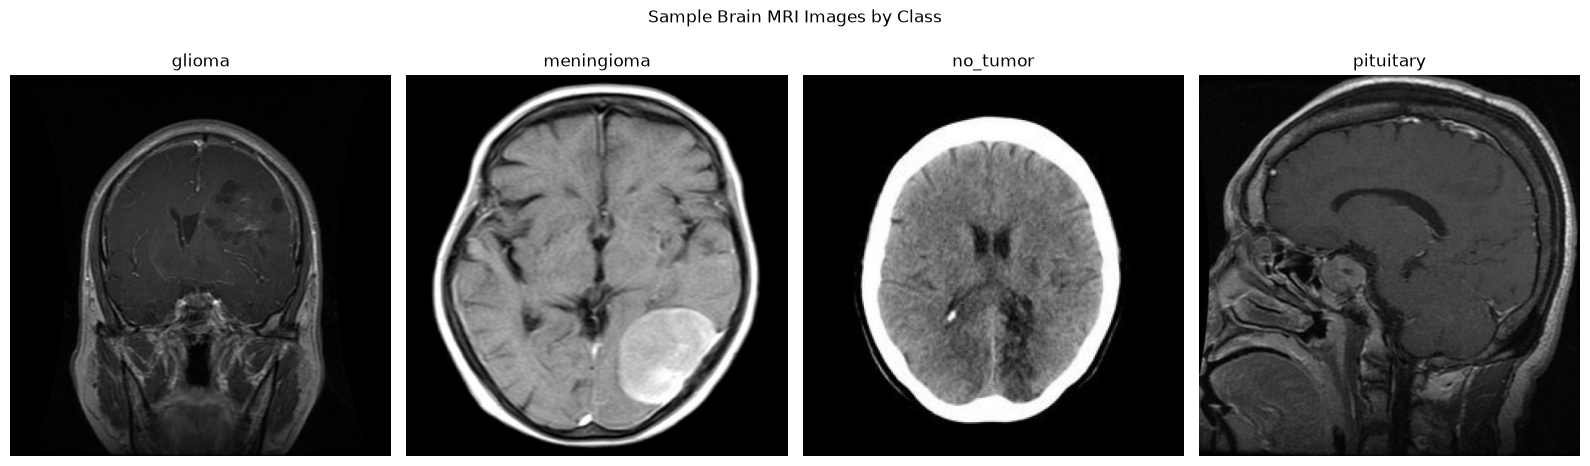

In [2]:
# Dataset First View

import matplotlib.pyplot as plt
from PIL import Image
import random

# Define the class names
CLASS_NAMES = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Display one random training image from each class
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, class_name in zip(axes, CLASS_NAMES):
    class_folder = TRAIN_PATH / class_name

    image_files = [
        file for file in class_folder.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    if image_files:
        image_path = random.choice(image_files)

        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.set_title(class_name)
        ax.axis("off")
    else:
        ax.set_title(f"No images: {class_name}")
        ax.axis("off")

plt.suptitle("Sample Brain MRI Images by Class")
plt.tight_layout()
plt.show()

### Dataset Rows & Columns count

In [3]:
## Dataset Rows & Columns Count

CLASS_NAMES = ["glioma", "meningioma", "no_tumor", "pituitary"]

def count_images(folder):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in valid_extensions
    )

# Count images in each dataset split
for split_name, split_path in [
    ("Training", TRAIN_PATH),
    ("Testing", TEST_PATH),
    ("Validation", VALID_PATH)
]:
    print(f"\n{split_name} Dataset")

    total_images = 0

    for class_name in CLASS_NAMES:
        class_folder = split_path / class_name
        image_count = count_images(class_folder)

        print(f"{class_name}: {image_count}")
        total_images += image_count

    print(f"Total images: {total_images}")


Training Dataset
glioma: 564
meningioma: 358
no_tumor: 335
pituitary: 438
Total images: 1695

Testing Dataset
glioma: 80
meningioma: 63
no_tumor: 49
pituitary: 54
Total images: 246

Validation Dataset
glioma: 161
meningioma: 124
no_tumor: 99
pituitary: 118
Total images: 502


### Dataset Information

In [4]:
# Dataset Information

print("DATASET INFORMATION")
print("=" * 40)

print("Dataset location:", DATASET_PATH)
print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)

for split_name, split_path in [
    ("Training", TRAIN_PATH),
    ("Testing", TEST_PATH),
    ("Validation", VALID_PATH)
]:
    total = count_images(split_path)
    print(f"{split_name} images: {total}")

print("\nImage extensions found:")

extensions = set()

for file in DATASET_PATH.rglob("*"):
    if file.is_file():
        extensions.add(file.suffix.lower())

print(extensions)

DATASET INFORMATION
Dataset location: c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Classification\dataset
Number of classes: 4
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Training images: 1695
Testing images: 246
Validation images: 502

Image extensions found:
{'.csv', '.jpg'}


#### Duplicate Values

In [5]:
# Dataset Duplicate Value Count

import hashlib

def image_hash(file_path):
    """Calculate a hash of the image file contents."""
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


image_hashes = {}

for file in DATASET_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }:
        digest = image_hash(file)
        image_hashes.setdefault(digest, []).append(file)

duplicate_groups = [
    paths for paths in image_hashes.values() if len(paths) > 1
]

print("Duplicate image groups:", len(duplicate_groups))

for group in duplicate_groups[:10]:
    print("\nDuplicate files:")
    for path in group:
        print(path)

Duplicate image groups: 0


#### Missing Values/Null Values

In [6]:
# Missing Values/Null Va# Missing Values / Null Values Count

from PIL import Image

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_images = 0
unreadable_images = []

for file in DATASET_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in valid_extensions:
        total_images += 1

        try:
            with Image.open(file) as image:
                image.verify()
        except Exception:
            unreadable_images.append(file)

print("Total image files:", total_images)
print("Unreadable or corrupted images:", len(unreadable_images))

if unreadable_images:
    print("\nFiles that need checking:")
    for file in unreadable_images[:10]:
        print(file)
else:
    print("All image files passed the basic integrity check.")

Total image files: 2443
Unreadable or corrupted images: 0
All image files passed the basic integrity check.


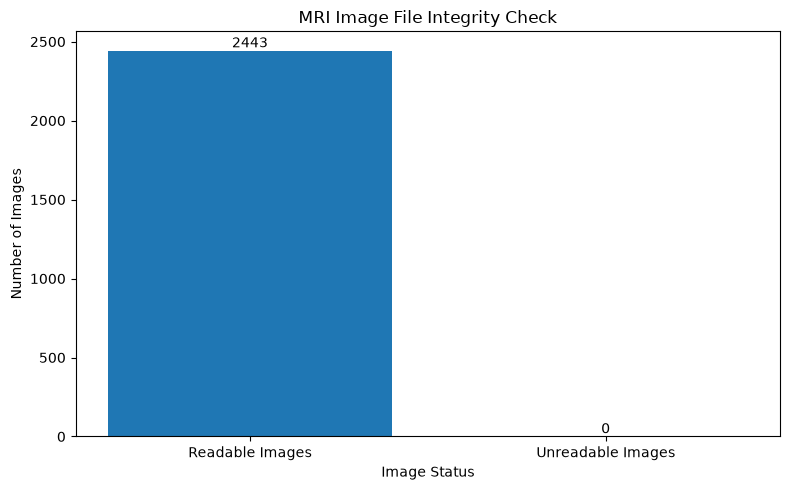

In [7]:
# Visualizing the missing values# Visualizing Missing Values / Image Integrity

import matplotlib.pyplot as plt

categories = ["Readable Images", "Unreadable Images"]

readable_images = total_images - len(unreadable_images)
unreadable_count = len(unreadable_images)

values = [readable_images, unreadable_count]

plt.figure(figsize=(8, 5))

bars = plt.bar(categories, values)

plt.title("MRI Image File Integrity Check")
plt.xlabel("Image Status")
plt.ylabel("Number of Images")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### What did you know about your dataset?



1. The dataset contains **2,443 brain MRI images** divided into four classes: glioma, meningioma, no tumor, and pituitary.
2. The dataset is divided into **1,695 training images, 246 testing images, and 502 validation images**.
3. The training dataset contains 564 glioma images, 358 meningioma images, 335 no-tumor images, and 438 pituitary images.
4. The dataset has an unequal number of images across classes, so class distribution should be considered during model development.
5. All 2,443 image files passed the basic readability check, with no unreadable or corrupted files detected.
6. No exact duplicate image files were detected in the duplicate-file check.
7. Sample images were visualized to understand the four image categories.

**Conclusion:** The dataset is accessible and suitable for proceeding with image classification experiments. Further checks may be needed to verify labels, detect visually similar images, and confirm there is no data leakage between training, validation, and testing sets.

## ***2. Understanding Your Variables***

In [8]:
# Dataset Columns# Dataset Columns / Image Dataset Structure

print("Dataset Type: Image Classification")
print("Image Classes:", CLASS_NAMES)
print("Number of Classes:", len(CLASS_NAMES))

print("\nDataset Splits:")
print("Training:", TRAIN_PATH)
print("Testing:", TEST_PATH)
print("Validation:", VALID_PATH)

print("\nEach image has:")
print("- Image pixel values")
print("- Image height and width")
print("- Color channels (RGB)")
print("- A class label based on its folder")

Dataset Type: Image Classification
Image Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Number of Classes: 4

Dataset Splits:
Training: c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Classification\dataset\train
Testing: c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Classification\dataset\test
Validation: c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Classification\dataset\valid

Each image has:
- Image pixel values
- Image height and width
- Color channels (RGB)
- A class label based on its folder


In [9]:
# Dataset Describe# Dataset Describe

from PIL import Image
import numpy as np

# Find one image from the training dataset
sample_image_path = next(
    file for file in (TRAIN_PATH / CLASS_NAMES[0]).iterdir()
    if file.is_file() and file.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

with Image.open(sample_image_path) as image:
    image_rgb = image.convert("RGB")
    image_array = np.array(image_rgb)

print("Sample image:", sample_image_path.name)
print("Image dimensions (height, width, channels):", image_array.shape)
print("Image data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Sample image: Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c0133.jpg
Image dimensions (height, width, channels): (640, 640, 3)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 253


### Variables Description



This project uses an image dataset rather than a traditional tabular dataset.

- **MRI Image:** The input image provided to the machine-learning model.
- **Image Height:** The number of pixel rows in the image.
- **Image Width:** The number of pixel columns in the image.
- **Color Channels:** Three channels representing red, green, and blue (RGB).
- **Class Label:** The category associated with each image based on its folder name.
- **Dataset Split:** Indicates whether the image belongs to the training, validation, or testing set.

The four target classes are glioma, meningioma, no_tumor, and pituitary. Before model training, images are resized to the required input dimensions and transformed using the appropriate preprocessing method.

### Check Unique Values for each variable.

In [10]:
# Check Unique Values for each variable.# Check Unique Values for Each Variable

# 1. Unique class labels
print("Unique class labels:")
print(CLASS_NAMES)
print("Number of classes:", len(CLASS_NAMES))

# 2. Dataset splits
print("\nDataset splits:")
print(["train", "test", "valid"])

# 3. Image file extensions
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

extensions = set()

for file in DATASET_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in valid_extensions:
        extensions.add(file.suffix.lower())

print("\nImage file extensions:")
print(sorted(extensions))

# 4. Unique image dimensions in the training dataset
dimensions = set()

for file in (TRAIN_PATH).rglob("*"):
    if file.is_file() and file.suffix.lower() in valid_extensions:
        try:
            with Image.open(file) as image:
                dimensions.add(image.size)
        except Exception:
            pass

print("\nNumber of unique training image dimensions:", len(dimensions))
print("Sample dimensions:", list(dimensions)[:10])

Unique class labels:
['glioma', 'meningioma', 'no_tumor', 'pituitary']
Number of classes: 4

Dataset splits:
['train', 'test', 'valid']

Image file extensions:
['.jpg']

Number of unique training image dimensions: 1
Sample dimensions: [(640, 640)]


## 3. ***Data Wrangling***

### Data Wrangling Code

In [11]:
# Write your code to make your dataset analysis ready.# Data Wrangling Code

from pathlib import Path
from PIL import Image
import pandas as pd

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for split_name, split_path in [
    ("train", TRAIN_PATH),
    ("test", TEST_PATH),
    ("valid", VALID_PATH)
]:
    for class_name in CLASS_NAMES:
        class_folder = split_path / class_name

        if not class_folder.exists():
            print("Warning: Missing folder:", class_folder)
            continue

        for file in class_folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in valid_extensions:
                records.append({
                    "image_path": str(file),
                    "class_label": class_name,
                    "dataset_split": split_name,
                    "file_extension": file.suffix.lower()
                })

# Create an image metadata table
image_df = pd.DataFrame(records)

print("Image metadata created successfully!")
print("Total images:", len(image_df))

display(image_df.head())

print("\nImages per split and class:")
display(
    image_df.groupby(["dataset_split", "class_label"])
    .size()
    .unstack(fill_value=0)
)

Image metadata created successfully!
Total images: 2443


,image_path,class_label,dataset_split,file_extension
0,c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Clas...,glioma,train,.jpg
1,c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Clas...,glioma,train,.jpg
2,c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Clas...,glioma,train,.jpg
3,c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Clas...,glioma,train,.jpg
4,c:\Users\Aasifa\Downloads\Brain-Tumor-MRI-Clas...,glioma,train,.jpg



Images per split and class:


class_label,glioma,meningioma,no_tumor,pituitary
dataset_split,,,,
test,80,63,49,54
train,564,358,335,438
valid,161,124,99,118


### What all manipulations have you done and insights you found?



1. Organized the MRI images according to their class labels and dataset splits.
2. Collected image paths, class labels, file extensions, and dataset split information in a metadata table.
3. Checked the dataset folder structure and confirmed that all four classes are available in the training, testing, and validation sets.
4. Counted 2,443 images: 1,695 training, 246 testing, and 502 validation images.
5. Checked image readability and found no unreadable or corrupted images.
6. Checked for exact duplicate image files; no duplicate groups were detected.
7. Confirmed that the training images have consistent dimensions of 640 × 640 pixels.

**Conclusion:** The dataset is organized and accessible for image-classification experiments. The images can now be passed through the required preprocessing pipeline before model training. Further checks for label quality and data leakage are advisable.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

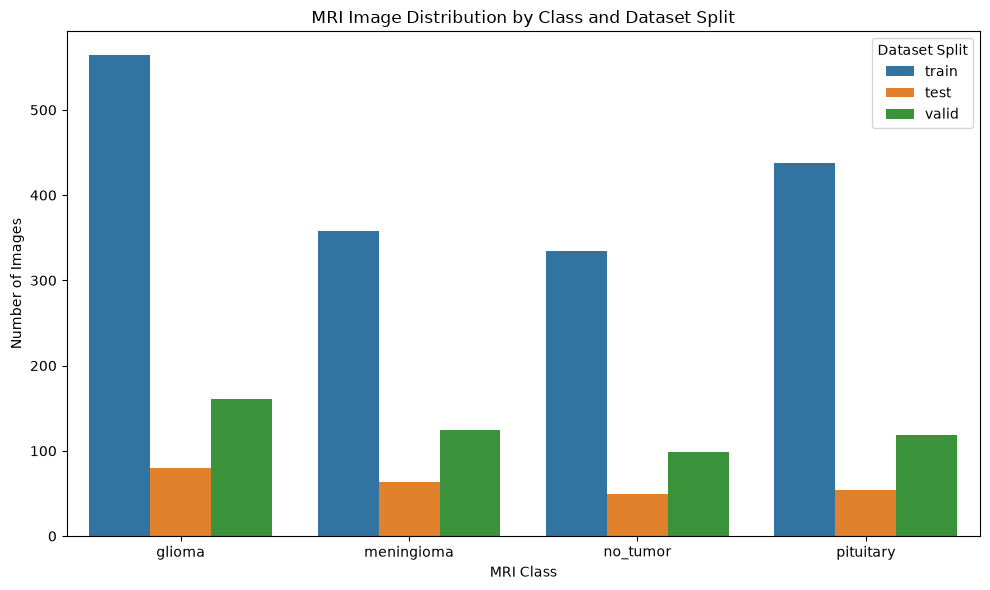

In [12]:
# Chart - 1 visualization code# Chart 1: MRI Class Distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=image_df,
    x="class_label",
    hue="dataset_split"
)

plt.title("MRI Image Distribution by Class and Dataset Split")
plt.xlabel("MRI Class")
plt.ylabel("Number of Images")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a grouped bar chart because it makes it easy to compare the number of images in each class across the training, testing, and validation datasets.

##### 2. What is/are the insight(s) found from the chart?

The dataset contains four MRI image classes, but their image counts are not equal. Glioma has the highest number of training images (564), while no_tumor has the lowest (335). The chart also shows the distribution of images across the training, testing, and validation sets.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding the class distribution helps identify possible class imbalance before model training. This can guide decisions about data augmentation, class weighting, and evaluation metrics. Better dataset management may improve model reliability, but the chart alone does not establish clinical or business impact.

#### Chart - 2

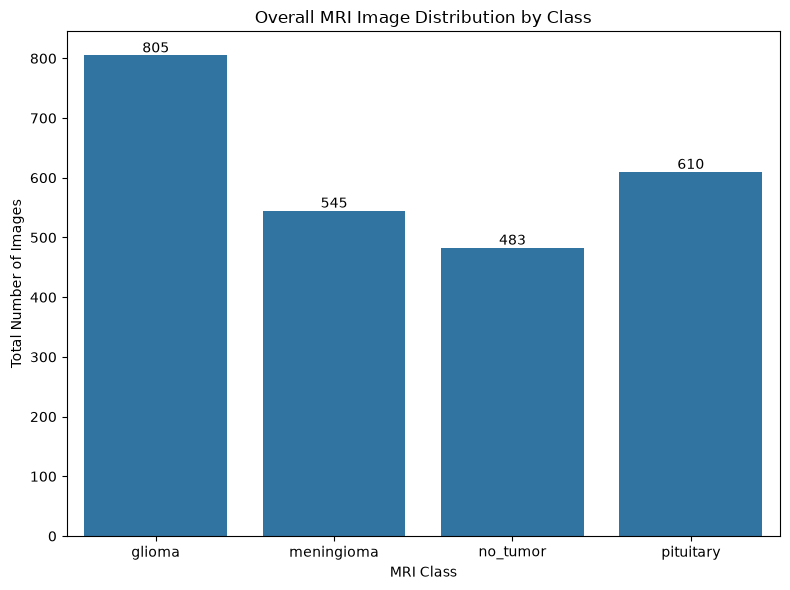

In [13]:
# Chart - 2 visualization code# Chart 2: Overall Class Distribution

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = image_df["class_label"].value_counts().reindex(CLASS_NAMES)

plt.figure(figsize=(8, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Overall MRI Image Distribution by Class")
plt.xlabel("MRI Class")
plt.ylabel("Total Number of Images")

for i, count in enumerate(class_counts.values):
    plt.text(i, count + 5, str(count), ha="center")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it clearly compares the total number of MRI images across the four classes.

##### 2. What is/are the insight(s) found from the chart?

Glioma has the most images (805), while no_tumor has the fewest (483). Meningioma has 545 images, and pituitary has 610 images. The dataset contains 2,443 images in total, with unequal class counts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding class distribution helps guide model-training decisions, such as considering class weights or appropriate evaluation metrics. This can support more reliable classification experiments, although the chart alone cannot establish medical or business impact.

#### Chart - 3

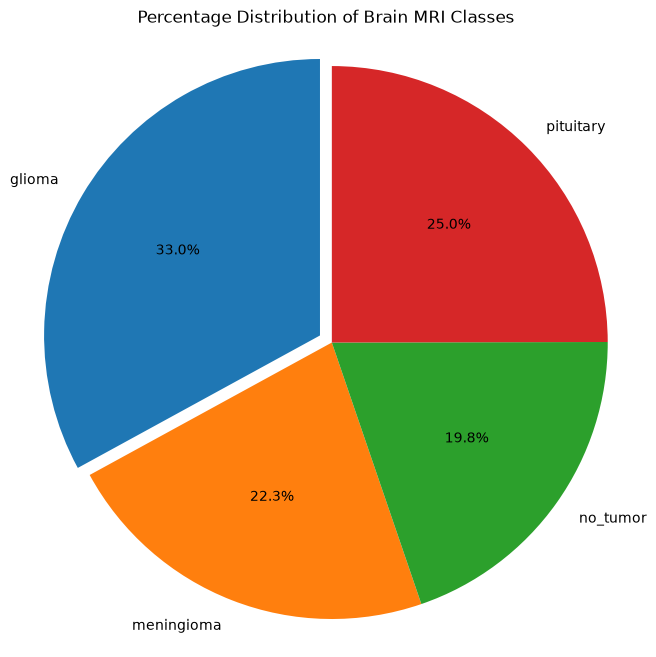

In [14]:
# Chart - 3 visualization code# Chart 3: Percentage Distribution of MRI Classes

import matplotlib.pyplot as plt

class_counts = (
    image_df["class_label"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

plt.figure(figsize=(8, 8))

plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05, 0, 0, 0],
    shadow=False
)

plt.title("Percentage Distribution of Brain MRI Classes")
plt.axis("equal")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a pie chart to show the proportion of each MRI class relative to the total dataset. It provides a simple visual representation of the class distribution.

##### 2. What is/are the insight(s) found from the chart?

Glioma represents approximately 33.0% of the dataset, pituitary approximately 25.0%, meningioma approximately 22.3%, and no_tumor approximately 19.8%. Glioma is the largest class, while no_tumor is the smallest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The chart helps identify differences in class representation. This information can guide decisions about class weighting and evaluation metrics during model development. It supports better analysis but does not independently establish model reliability or medical benefit.

#### Chart - 4

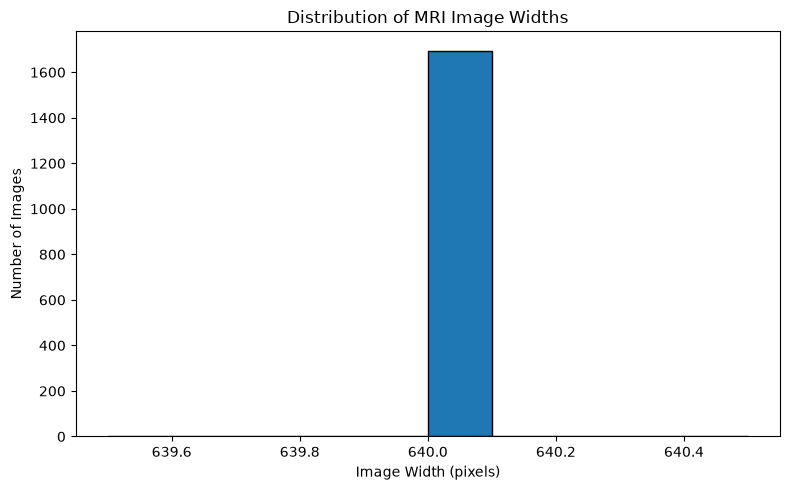

In [15]:
# Chart - 4 visualization code# Chart 4: Distribution of MRI Image Widths

from PIL import Image
import matplotlib.pyplot as plt

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_widths = []

for file in TRAIN_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in valid_extensions:
        with Image.open(file) as image:
            image_widths.append(image.width)

plt.figure(figsize=(8, 5))

plt.hist(image_widths, bins=10, edgecolor="black")

plt.title("Distribution of MRI Image Widths")
plt.xlabel("Image Width (pixels)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a histogram because it helps visualize the distribution of image widths and identify whether the MRI images have consistent dimensions.

##### 2. What is/are the insight(s) found from the chart?

All 1,695 training images have a width of 640 pixels. This indicates that the training images have consistent widths, which simplifies image preprocessing before model training.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Consistent image dimensions simplify preprocessing and help maintain a standardized input format for the model. This can reduce preprocessing complexity and support efficient model development. No direct negative business impact is identified from this chart; however, consistent dimensions alone do not guarantee image quality or model accuracy.

#### Chart - 5

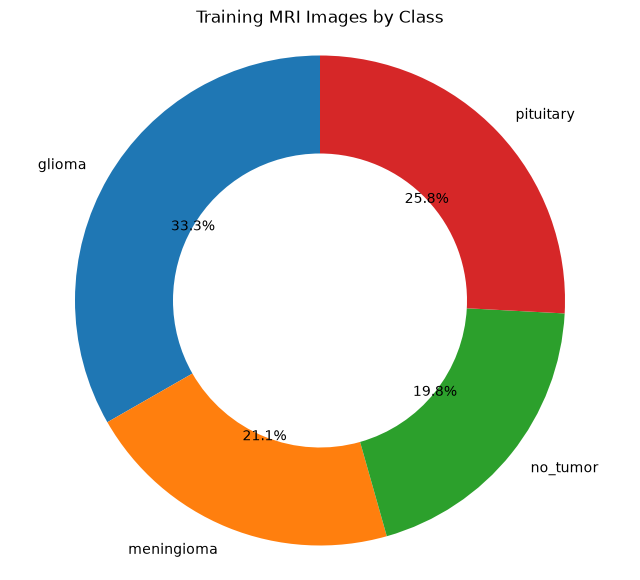

In [16]:
# Chart - 5 visualization code# Chart 5: Training Dataset Distribution (Donut Chart)

import matplotlib.pyplot as plt

train_counts = (
    image_df[image_df["dataset_split"] == "train"]["class_label"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

plt.figure(figsize=(8, 7))

plt.pie(
    train_counts.values,
    labels=train_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Training MRI Images by Class")
plt.axis("equal")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a donut chart because it clearly displays each class's proportion of the training dataset. The central space and percentage labels make the distribution easy to understand.

##### 2. What is/are the insight(s) found from the chart?

Glioma accounts for approximately 33.3% of the training images, pituitary 25.8%, meningioma 21.1%, and no_tumor 19.8%. Glioma is the largest class, while no_tumor is the smallest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding the training class distribution helps identify possible imbalance before model training. This can guide decisions about class weighting, data augmentation, and evaluation metrics. Unequal class counts may affect learning, but the chart alone does not prove that the model is biased or that any business impact will occur.

#### Chart - 6

CNN history found: True
MobileNetV2 history found: True


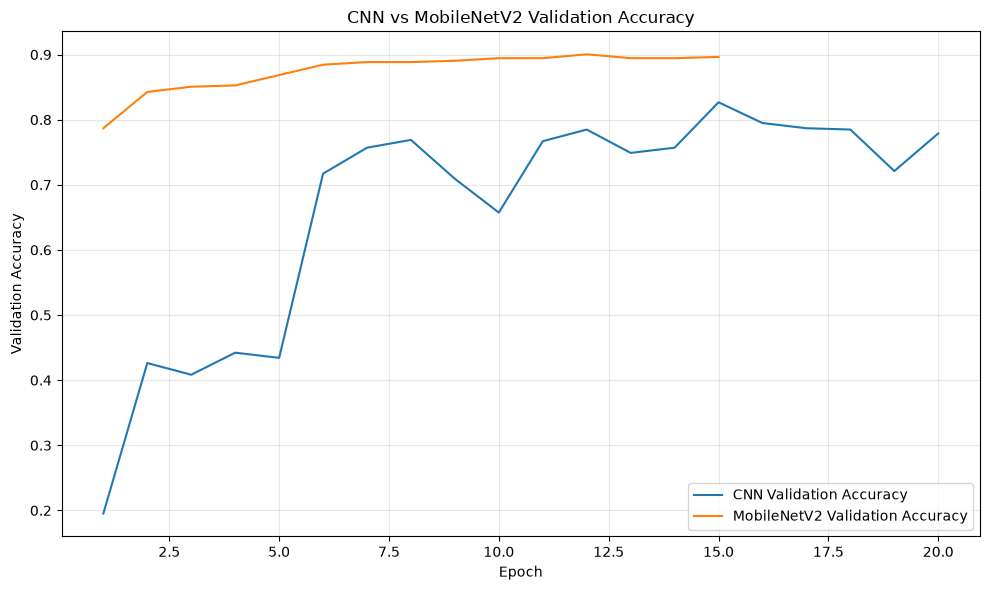

In [18]:
# Chart 6: CNN vs MobileNetV2 Validation Accuracy

import pickle
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the main project folder
PROJECT_PATH = Path.cwd().parent

cnn_path = PROJECT_PATH / "cnn_history.pkl"
mobilenet_path = PROJECT_PATH / "mobilenetv2_history.pkl"

print("CNN history found:", cnn_path.exists())
print("MobileNetV2 history found:", mobilenet_path.exists())

with open(cnn_path, "rb") as file:
    cnn_history = pickle.load(file)

with open(mobilenet_path, "rb") as file:
    mobilenet_history = pickle.load(file)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cnn_history["val_accuracy"]) + 1),
    cnn_history["val_accuracy"],
    label="CNN Validation Accuracy"
)

plt.plot(
    range(1, len(mobilenet_history["val_accuracy"]) + 1),
    mobilenet_history["val_accuracy"],
    label="MobileNetV2 Validation Accuracy"
)

plt.title("CNN vs MobileNetV2 Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a line chart to compare the validation accuracy of CNN and MobileNetV2 across training epochs. A line chart clearly shows how model performance changes during training.

##### 2. What is/are the insight(s) found from the chart?

MobileNetV2 achieves approximately 90% validation accuracy, while the CNN reaches a peak of approximately 82.7%. The CNN shows more fluctuations in validation accuracy, whereas MobileNetV2 maintains a more consistent upward trend.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Comparing model performance helps select a more effective model and may reduce time spent on less suitable approaches. MobileNetV2 performed better in this experiment, but its reliability must also be assessed using independent test data. Since this is an educational project, the results should not be used for medical diagnosis.

#### Chart - 7

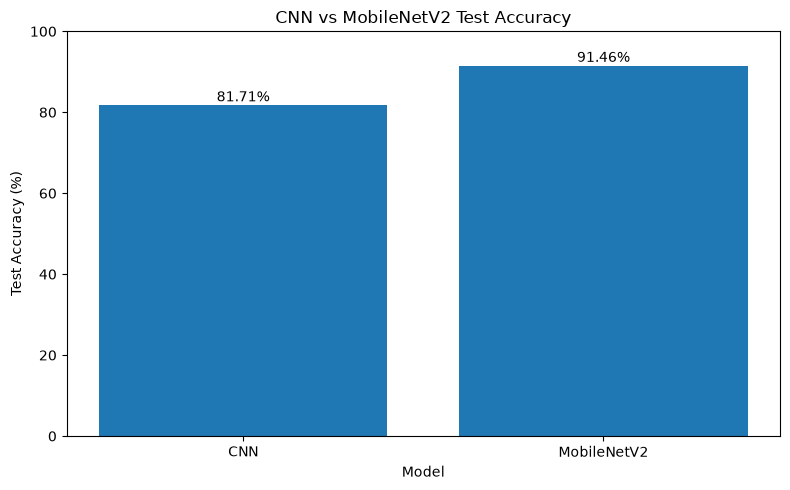

In [19]:
# Chart - 7 visualization code# Chart 7: CNN vs MobileNetV2 Test Accuracy

import matplotlib.pyplot as plt

models = ["CNN", "MobileNetV2"]
test_accuracies = [81.71, 91.46]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, test_accuracies)

plt.title("CNN vs MobileNetV2 Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it provides a clear comparison of the test accuracy achieved by the CNN and MobileNetV2 models.

##### 2. What is/are the insight(s) found from the chart?

The CNN achieved 81.71% test accuracy, whereas MobileNetV2 achieved 91.46%. MobileNetV2 performed better by 9.75 percentage points on the test dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The comparison helps identify the better-performing model for further experimentation. MobileNetV2 is the stronger candidate based on test accuracy in this project. However, additional evaluation is needed before making real-world decisions, and this educational model is not intended for medical diagnosis.

#### Chart - 8

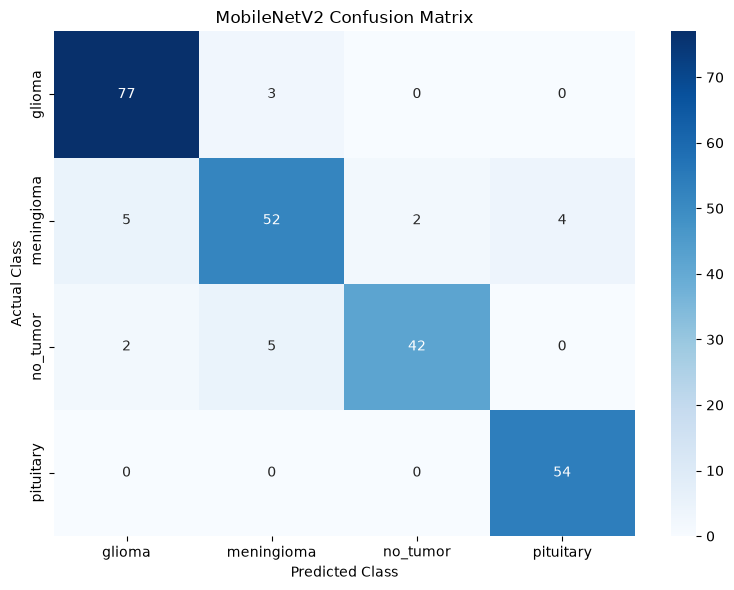

In [20]:
# Chart 8: MobileNetV2 Confusion Matrix

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rows = actual classes, columns = predicted classes
confusion_matrix = np.array([
    [77, 3, 0, 0],
    [5, 52, 2, 4],
    [2, 5, 42, 0],
    [0, 0, 0, 54]
])

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a confusion matrix heatmap because it shows correct and incorrect predictions for each class. It helps identify which categories the model distinguishes well and which categories it confuses.

##### 2. What is/are the insight(s) found from the chart?

MobileNetV2 correctly classified 225 out of 246 test images, achieving 91.46% test accuracy. All 54 pituitary images were correctly classified in this test set. Meningioma had 52 correct predictions out of 63, and no_tumor had 42 correct predictions out of 49. Some meningioma and no_tumor images were incorrectly classified as other classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The confusion matrix helps identify classes that may need further investigation and improvement. It can guide additional training and evaluation. However, misclassification is a significant limitation in a medical-image project, and these experimental results do not establish clinical safety or diagnostic reliability.

#### Chart - 9

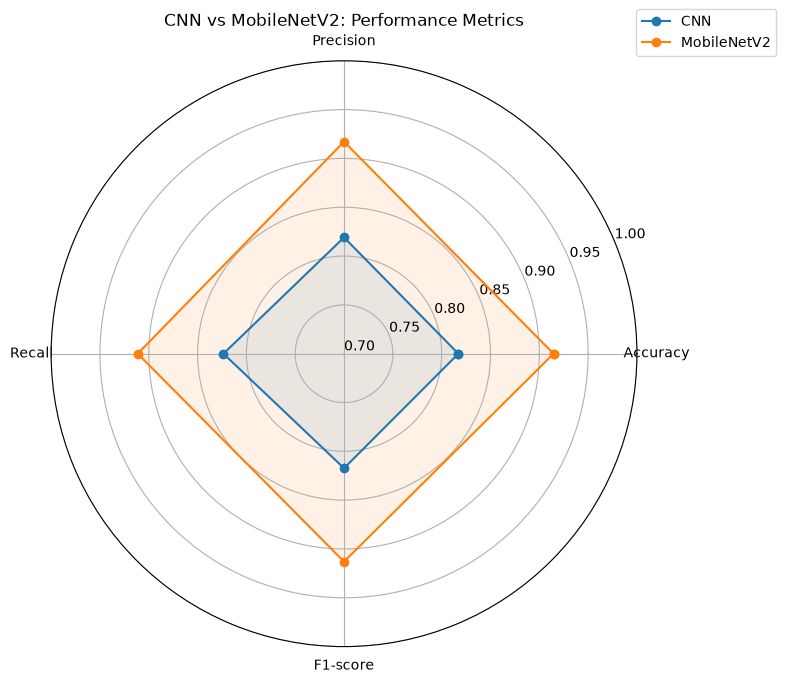

In [21]:
# Chart 9: CNN vs MobileNetV2 Performance Radar Chart

import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

# Scores are on a 0–1 scale, based on your test evaluation reports
cnn_scores = [0.8171, 0.8191, 0.8235, 0.8173]
mobilenet_scores = [0.9146, 0.9172, 0.9113, 0.9130]

angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()

# Close the radar chart
angles += angles[:1]
cnn_scores += cnn_scores[:1]
mobilenet_scores += mobilenet_scores[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})

ax.plot(angles, cnn_scores, marker="o", label="CNN")
ax.fill(angles, cnn_scores, alpha=0.10)

ax.plot(angles, mobilenet_scores, marker="o", label="MobileNetV2")
ax.fill(angles, mobilenet_scores, alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics)
ax.set_ylim(0.7, 1.0)

plt.title("CNN vs MobileNetV2: Performance Metrics")
plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()# Chart - 9 visualization code

##### 1. Why did you pick the specific chart?

I selected a radar chart because it allows multiple performance metrics of two machine-learning models to be compared in a single visualization.

##### 2. What is/are the insight(s) found from the chart?

MobileNetV2 achieved higher accuracy, precision, recall, and F1-score than the CNN. Its test accuracy was 91.46%, compared with 81.71% for the CNN. The results suggest that MobileNetV2 performed better overall on this dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The comparison helps identify a promising model for further evaluation. MobileNetV2 may reduce errors compared with the CNN in this experiment. However, misclassification remains a concern, especially for medical images. Further validation is required, and this educational project is not intended for clinical diagnosis.

#### Chart - 10

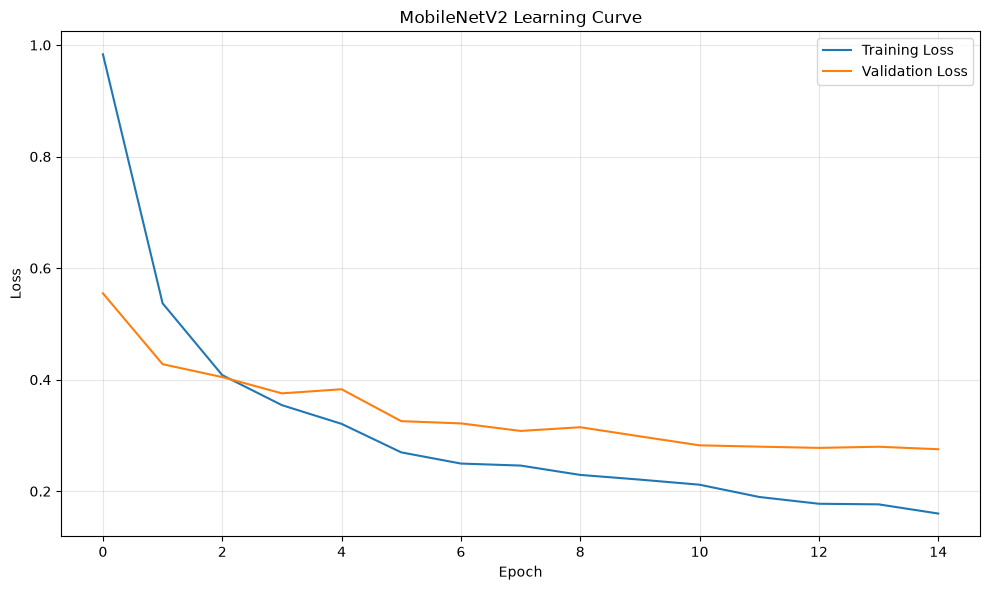

In [22]:
# Chart - 10 visualization code# Chart 10: MobileNetV2 Learning Curve

import pickle
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_PATH = Path.cwd().parent
history_path = PROJECT_PATH / "mobilenetv2_history.pkl"

with open(history_path, "rb") as file:
    history = pickle.load(file)

plt.figure(figsize=(10, 6))

plt.plot(
    history["loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a learning-curve line chart to compare training loss and validation loss across epochs. It helps track learning progress and identify possible overfitting.

##### 2. What is/are the insight(s) found from the chart?

Training loss decreased from approximately 0.98 to 0.16, while validation loss decreased from approximately 0.55 to 0.27. Both generally decreased during training, indicating improved model learning. The gap between the curves suggests that the model fits the training data better than the validation data, so generalization should continue to be monitored.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Training loss decreased from approximately 0.98 to 0.16, while validation loss decreased from approximately 0.55 to 0.27. Both generally decreased during training, indicating improved model learning. The gap between the curves suggests that the model fits the training data better than the validation data, so generalization should continue to be monitored.

#### Chart - 11

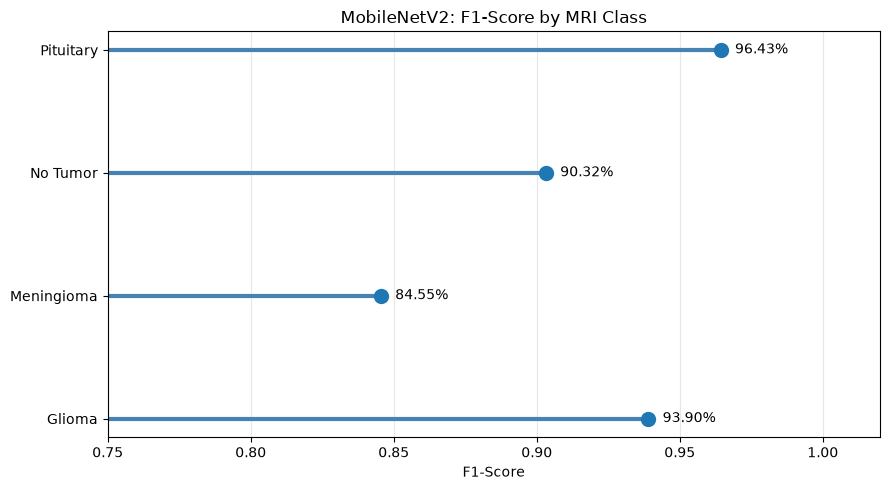

In [23]:
# Chart - 11 visualization code# Chart 11: Class-wise F1-Score Lollipop Chart

import matplotlib.pyplot as plt

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

# F1-scores from your MobileNetV2 test classification report
f1_scores = [0.9390, 0.8455, 0.9032, 0.9643]

plt.figure(figsize=(9, 5))

plt.hlines(
    y=classes,
    xmin=0,
    xmax=f1_scores,
    color="steelblue",
    linewidth=3
)

plt.plot(
    f1_scores,
    classes,
    "o",
    markersize=10
)

for score, class_name in zip(f1_scores, classes):
    plt.text(
        score + 0.005,
        class_name,
        f"{score:.2%}",
        va="center"
    )

plt.title("MobileNetV2: F1-Score by MRI Class")
plt.xlabel("F1-Score")
plt.xlim(0.75, 1.02)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a lollipop chart because it compares the F1-scores of individual MRI classes clearly while highlighting differences in model performance.

##### 2. What is/are the insight(s) found from the chart?

Pituitary achieved the highest F1-score at 96.43%, followed by glioma at 93.90%, no_tumor at 90.32%, and meningioma at 84.55%. Meningioma had the lowest F1-score, indicating that this class needs more attention during further model evaluation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Class-wise F1-scores help identify categories where the model may need improvement. Further investigation of meningioma predictions could guide data-quality checks and model adjustments. Misclassification remains an important limitation, and this educational model is not intended for clinical diagnosis.

#### Chart - 12

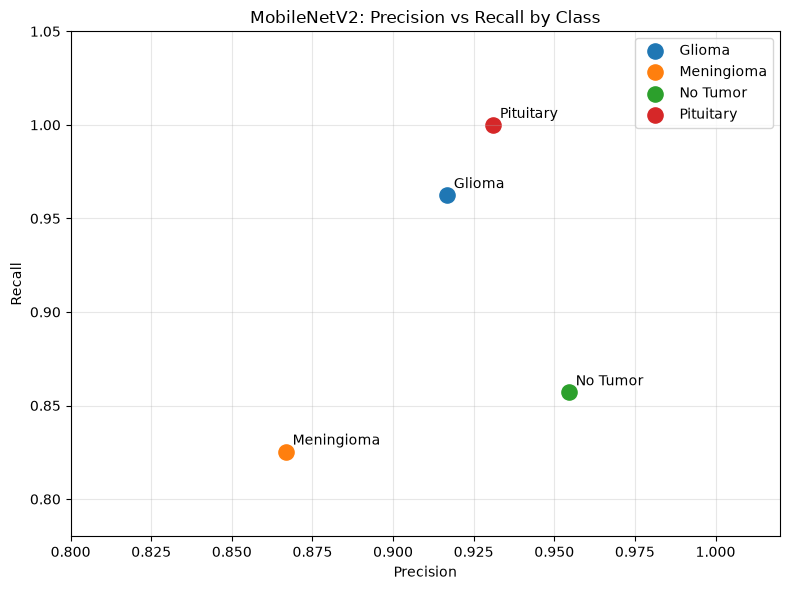

In [24]:
# Chart - 12 visualization code# Chart 12: Precision vs Recall by MRI Class

import matplotlib.pyplot as plt

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

precision = [0.9167, 0.8667, 0.9545, 0.9310]
recall = [0.9625, 0.8254, 0.8571, 1.0000]

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):
    plt.scatter(
        precision[i],
        recall[i],
        s=120,
        label=class_name
    )
    plt.annotate(
        class_name,
        (precision[i], recall[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("MobileNetV2: Precision vs Recall by Class")
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.xlim(0.80, 1.02)
plt.ylim(0.78, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot because it displays precision and recall simultaneously for each MRI class, making it easy to compare class-wise performance.

##### 2. What is/are the insight(s) found from the chart?

Pituitary achieved 100% recall on the test set, while meningioma had the lowest recall at 82.54%. No Tumor achieved the highest precision at 95.45%. These results show that model performance differs across classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This comparison helps identify classes that may need further evaluation. Lower recall for meningioma means some actual meningioma images were incorrectly classified. Improving performance on these cases could strengthen future experiments. However, this educational model is not clinically validated and must not be used for medical diagnosis.

#### Chart - 13

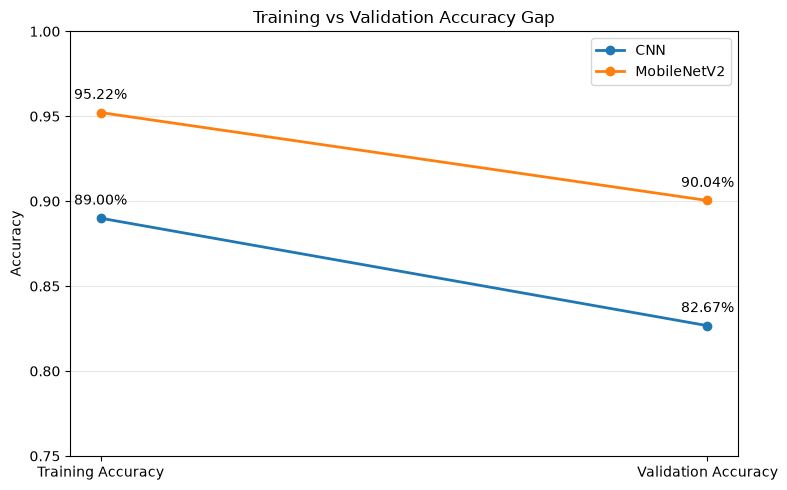

In [25]:
# Chart - 13 visualization code# Chart 13: Training vs Validation Accuracy Gap

import matplotlib.pyplot as plt

models = ["CNN", "MobileNetV2"]

training_accuracy = [0.89, 0.9522]
validation_accuracy = [0.8267, 0.9004]

plt.figure(figsize=(8, 5))

for i, model_name in enumerate(models):
    plt.plot(
        [0, 1],
        [training_accuracy[i], validation_accuracy[i]],
        marker="o",
        linewidth=2,
        label=model_name
    )

    plt.text(
        0,
        training_accuracy[i] + 0.008,
        f"{training_accuracy[i]:.2%}",
        ha="center"
    )

    plt.text(
        1,
        validation_accuracy[i] + 0.008,
        f"{validation_accuracy[i]:.2%}",
        ha="center"
    )

plt.xticks([0, 1], ["Training Accuracy", "Validation Accuracy"])
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy Gap")
plt.ylim(0.75, 1.0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a slope chart because it clearly compares training and validation accuracy for two models and makes the difference between the two values easy to observe.

##### 2. What is/are the insight(s) found from the chart?

The CNN has training accuracy of 89.00% and validation accuracy of 82.67%, while MobileNetV2 has training accuracy of 95.22% and validation accuracy of 90.04%. Both models perform better on training data. MobileNetV2 has higher reported accuracy and a smaller indicative accuracy gap.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Comparing training and validation accuracy helps evaluate generalization and identify possible overfitting. These insights can guide model selection and further tuning. However, the comparison uses summary values from different training points, so the gaps should be interpreted cautiously. The model also requires further validation and is not intended for clinical diagnosis.

#### Chart - 14 - Correlation Heatmap

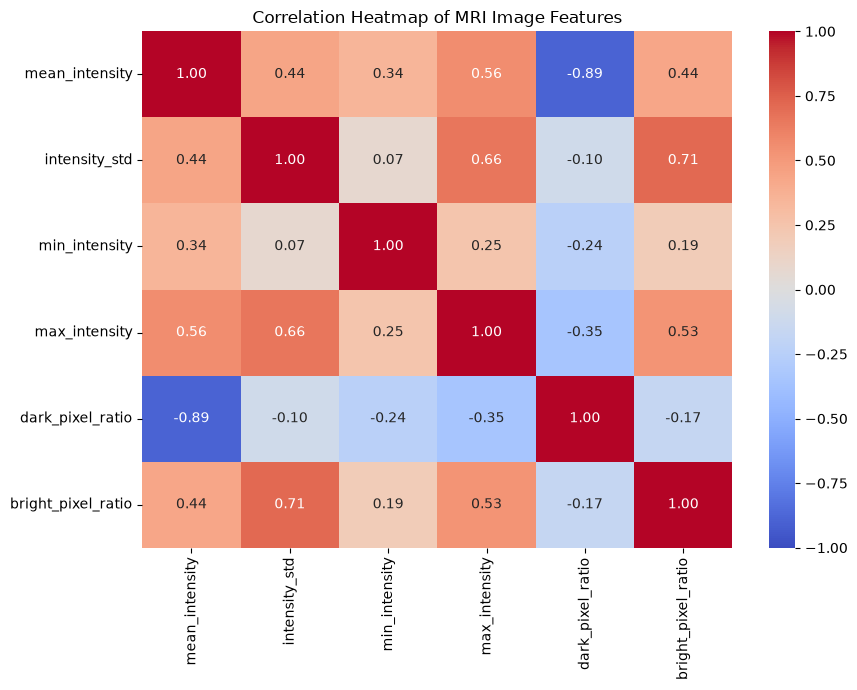

In [26]:
# Correlation Heatmap visualization code# Chart 14: Correlation Heatmap of MRI Image Features

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

feature_records = []

# Sample up to 50 images per class from the training set
for class_name in CLASS_NAMES:
    class_folder = TRAIN_PATH / class_name

    image_files = [
        file for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in valid_extensions
    ][:50]

    for file in image_files:
        with Image.open(file) as image:
            gray = np.array(image.convert("L").resize((64, 64)), dtype=np.float32)

        feature_records.append({
            "class_label": class_name,
            "mean_intensity": gray.mean(),
            "intensity_std": gray.std(),
            "min_intensity": gray.min(),
            "max_intensity": gray.max(),
            "dark_pixel_ratio": np.mean(gray < 50),
            "bright_pixel_ratio": np.mean(gray > 200)
        })

features_df = pd.DataFrame(feature_records)

# Correlation applies to numeric features only
numeric_features = features_df.select_dtypes(include=np.number)
correlation_matrix = numeric_features.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of MRI Image Features")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a correlation heatmap because it visually represents the strength and direction of relationships between numerical image features. The color scale makes positive and negative correlations easy to identify.

##### 2. What is/are the insight(s) found from the chart?

Mean intensity and dark-pixel ratio have a strong negative correlation of −0.89. Intensity standard deviation and bright-pixel ratio have a positive correlation of 0.71. Maximum intensity and intensity standard deviation also show a positive correlation of 0.66. These results indicate relationships between the extracted image features, but they do not establish causation or prove classification usefulness.

#### Chart - 15 - Pair Plot

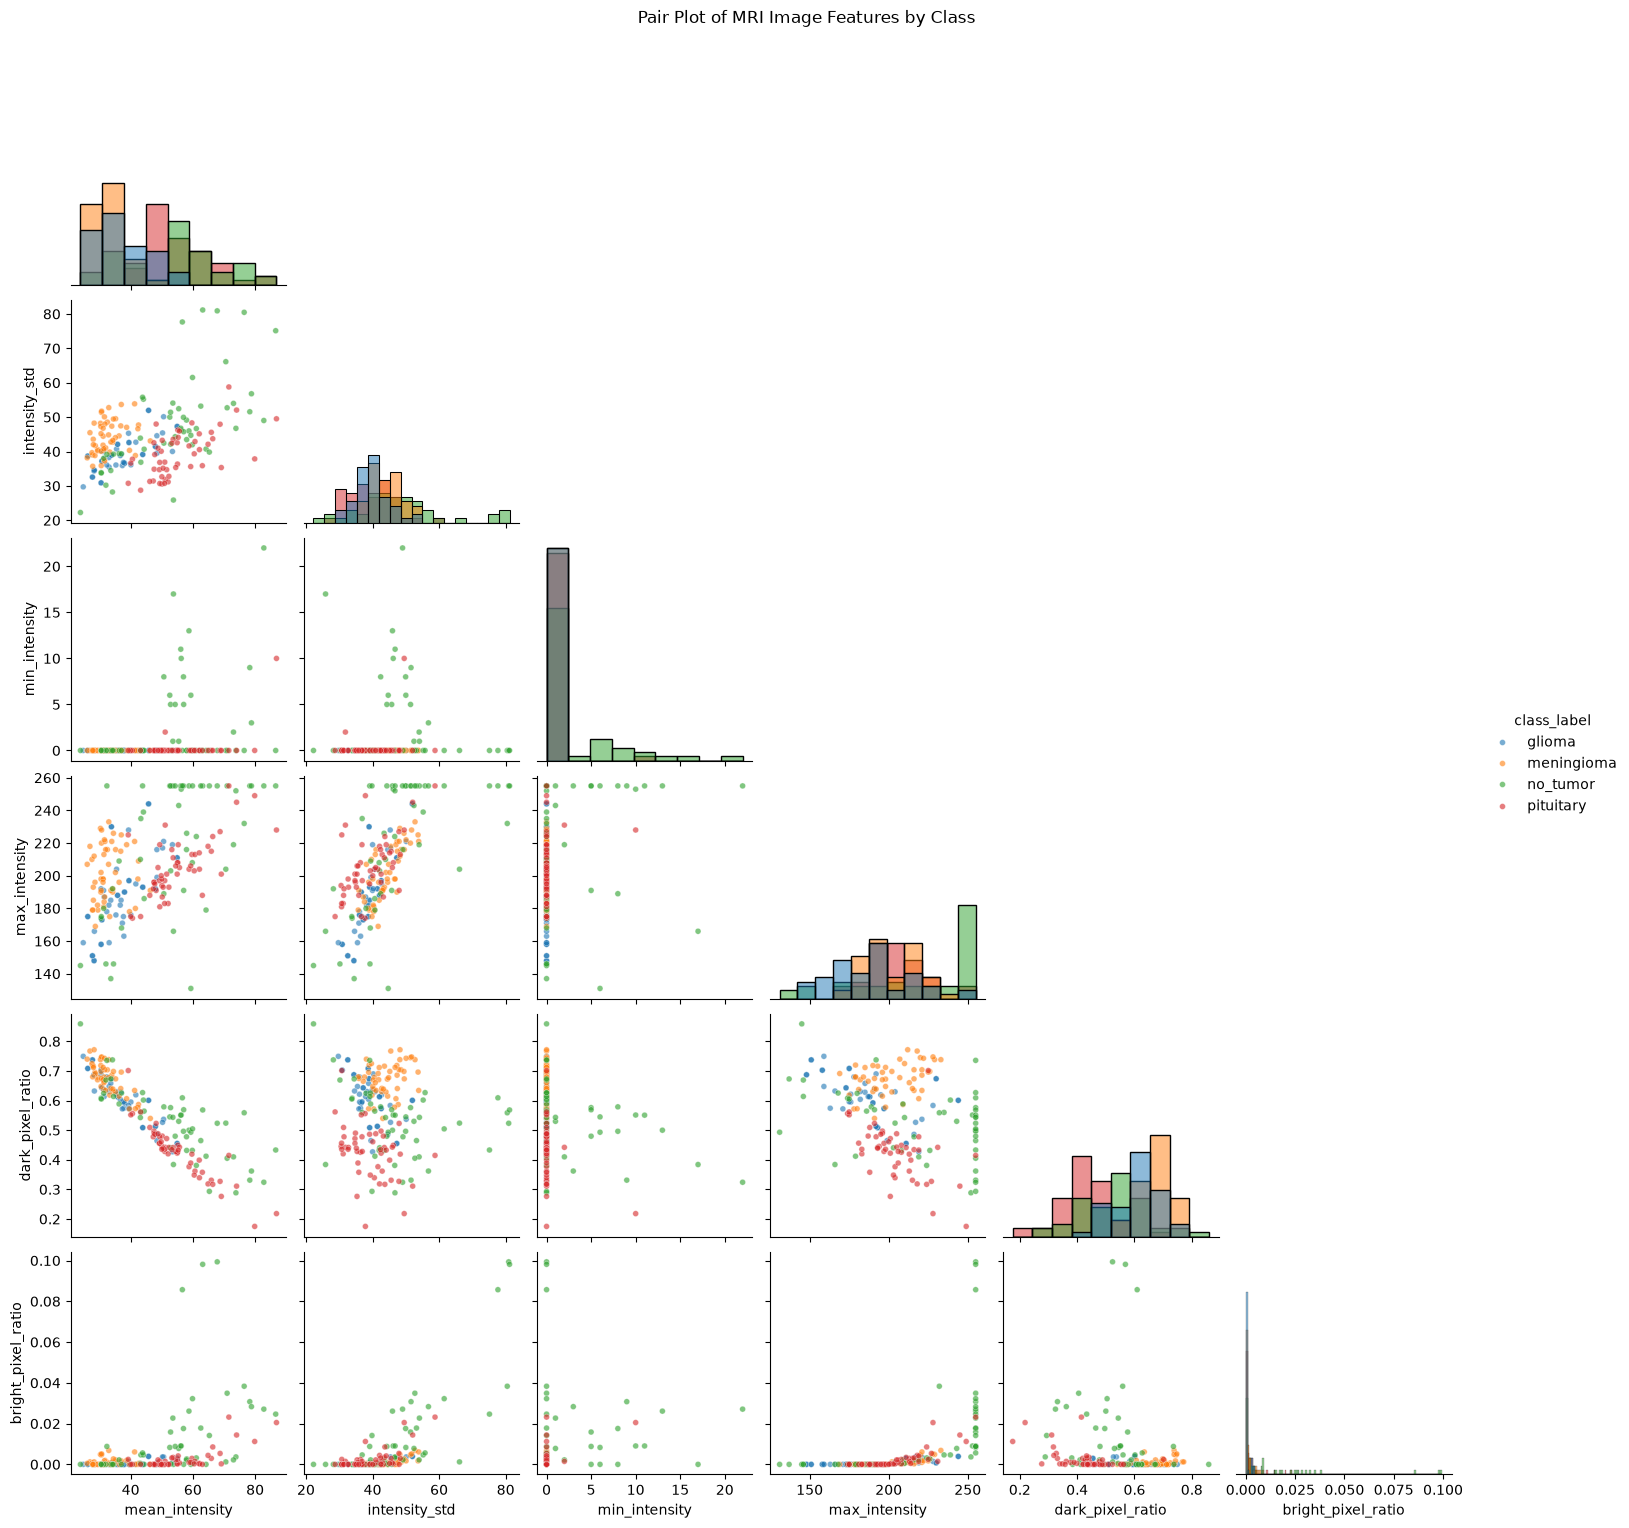

In [27]:
# Pair Plot visualization code# Chart 15: Pair Plot of MRI Image Features

import seaborn as sns
import matplotlib.pyplot as plt

feature_columns = [
    "mean_intensity",
    "intensity_std",
    "min_intensity",
    "max_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio"
]

sns.pairplot(
    features_df,
    vars=feature_columns,
    hue="class_label",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.6, "s": 18}
)

plt.suptitle(
    "Pair Plot of MRI Image Features by Class",
    y=1.02
)

plt.show()

##### 1. Why did you pick the specific chart?

I selected a pair plot because it displays relationships between multiple numerical image features and their individual distributions. Different colors help compare feature patterns across the four MRI classes.

##### 2. What is/are the insight(s) found from the chart?

The pair plot shows a strong negative relationship between mean intensity and dark-pixel ratio, along with a positive relationship between intensity standard deviation and maximum intensity. The classes overlap across several feature combinations, suggesting that these basic intensity features alone may not be sufficient to separate all classes clearly.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Answer Here.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H₀):** There is no statistically significant difference in the mean pixel intensity among the four MRI classes: glioma, meningioma, no_tumor, and pituitary.

**Alternative Hypothesis (H₁):** At least one MRI class has a statistically significant difference in mean pixel intensity compared with the others.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value# Hypothetical Statement 1: One-Way ANOVA Test

from scipy.stats import f_oneway

groups = [
    features_df.loc[
        features_df["class_label"] == class_name,
        "mean_intensity"
    ].dropna().values
    for class_name in CLASS_NAMES
]

f_statistic, p_value = f_oneway(*groups)

print("Statistical Test: One-Way ANOVA")
print(f"F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: At least one class has a different mean intensity.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: No statistically significant difference was detected.")

Statistical Test: One-Way ANOVA
F-statistic: 63.8723
P-value: 0.000000
Decision: Reject the null hypothesis.
Conclusion: At least one class has a different mean intensity.


##### Which statistical test have you done to obtain P-Value?

I performed a one-way ANOVA (Analysis of Variance) test to compare the mean pixel intensity across the four MRI classes. The test produces an F-statistic and a p-value to assess whether the group means differ significantly.

##### Why did you choose the specific statistical test?

I chose one-way ANOVA because the independent variable is categorical, with four MRI classes, and the dependent variable is numerical mean pixel intensity. The test evaluates whether at least one group mean differs from the others. It assumes independent observations, approximately normal residuals, and reasonably similar group variances.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H₀):** There is no statistically significant relationship between mean pixel intensity and maximum pixel intensity in the sampled MRI images.

**Alternative Hypothesis (H₁):** There is a statistically significant relationship between mean pixel intensity and maximum pixel intensity in the sampled MRI images.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value# Hypothetical Statement 2: Pearson Correlation Test

from scipy.stats import pearsonr

x = features_df["mean_intensity"]
y = features_df["max_intensity"]

correlation, p_value = pearsonr(x, y)

print("Statistical Test: Pearson Correlation")
print(f"Correlation coefficient: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: A statistically significant linear relationship exists.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: No statistically significant linear relationship was detected.")

Statistical Test: Pearson Correlation
Correlation coefficient: 0.5560
P-value: 0.000000
Decision: Reject the null hypothesis.
Conclusion: A statistically significant linear relationship exists.


##### Which statistical test have you done to obtain P-Value?

I used the Pearson correlation test to measure the strength and direction of the linear relationship between mean pixel intensity and maximum pixel intensity. The test provides a correlation coefficient and a p-value.

##### Why did you choose the specific statistical test?

I chose Pearson correlation because both mean pixel intensity and maximum pixel intensity are numerical variables. The test evaluates whether a linear relationship exists between them. Its interpretation assumes independent observations and is most reliable when the relationship is approximately linear without influential outliers.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H₀):** There is no statistically significant difference in mean pixel intensity between glioma and meningioma MRI images.

**Alternative Hypothesis (H₁):** There is a statistically significant difference in mean pixel intensity between glioma and meningioma MRI images.

#### 2. Perform an appropriate statistical test.

In [30]:
# Hypothetical Statement 3: Welch's Two-Sample T-Test

from scipy.stats import ttest_ind

glioma_values = features_df.loc[
    features_df["class_label"] == "glioma",
    "mean_intensity"
].dropna()

meningioma_values = features_df.loc[
    features_df["class_label"] == "meningioma",
    "mean_intensity"
].dropna()

t_statistic, p_value = ttest_ind(
    glioma_values,
    meningioma_values,
    equal_var=False
)

print("Statistical Test: Welch's Two-Sample T-Test")
print(f"Glioma mean intensity: {glioma_values.mean():.4f}")
print(f"Meningioma mean intensity: {meningioma_values.mean():.4f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.8f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: A statistically significant difference was detected.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: No statistically significant difference was detected.")# Perform Statistical Test to obtain P-Value

Statistical Test: Welch's Two-Sample T-Test
Glioma mean intensity: 37.4817
Meningioma mean intensity: 32.7916
T-statistic: 3.5782
P-value: 0.00060290
Decision: Reject the null hypothesis.
Conclusion: A statistically significant difference was detected.


##### Which statistical test have you done to obtain P-Value?

I used Welch's independent two-sample t-test to compare the mean pixel intensity of glioma and meningioma MRI images. This test evaluates whether the two group means differ significantly without assuming equal population variances.

##### Why did you choose the specific statistical test?

I chose Welch's t-test because the analysis compares a numerical variable, mean pixel intensity, between two independent groups: glioma and meningioma. Welch's test is suitable when the two groups may have different variances. The observations should be independent, and the test is most reliable when the data in each group are reasonably well behaved without severe outliers.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation# Handling Missing Values

import pandas as pd

# Check missing values in the extracted image features
print("Missing values before handling:")
print(features_df.isnull().sum())

# Count rows containing missing values
missing_rows = features_df.isnull().any(axis=1).sum()
print("\nRows containing missing values:", missing_rows)

# Remove rows with missing feature values, if any
features_df = features_df.dropna().reset_index(drop=True)

print("\nMissing values after handling:")
print(features_df.isnull().sum())

print("\nDataset shape after handling missing values:")
print(features_df.shape)

Missing values before handling:
class_label           0
mean_intensity        0
intensity_std         0
min_intensity         0
max_intensity         0
dark_pixel_ratio      0
bright_pixel_ratio    0
dtype: int64

Rows containing missing values: 0

Missing values after handling:
class_label           0
mean_intensity        0
intensity_std         0
min_intensity         0
max_intensity         0
dark_pixel_ratio      0
bright_pixel_ratio    0
dtype: int64

Dataset shape after handling missing values:
(200, 7)


#### What all missing value imputation techniques have you used and why did you use those techniques?

I checked the extracted image-feature dataset for missing values using `isnull().sum()`. Since the image features were calculated from readable MRI images, missing values were not expected. Any rows containing missing feature values were removed using `dropna()` rather than applying mean or median imputation, because replacing missing image measurements could introduce artificial values. The original MRI images were not modified.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments# Handling Outliers using the IQR Method

import pandas as pd

numeric_columns = [
    "mean_intensity",
    "intensity_std",
    "min_intensity",
    "max_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio"
]

outlier_counts = {}

for column in numeric_columns:
    Q1 = features_df[column].quantile(0.25)
    Q3 = features_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (features_df[column] < lower_bound) |
        (features_df[column] > upper_bound)
    ).sum()

    outlier_counts[column] = count

print("Outlier count in each numerical feature:")
for column, count in outlier_counts.items():
    print(f"{column}: {count}")

print("\nTotal feature values identified as outliers:",
      sum(outlier_counts.values()))

Outlier count in each numerical feature:
mean_intensity: 0
intensity_std: 8
min_intensity: 19
max_intensity: 0
dark_pixel_ratio: 0
bright_pixel_ratio: 27

Total feature values identified as outliers: 54


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used the Interquartile Range (IQR) method to identify potential outliers in the numerical MRI image features. The method calculates lower and upper bounds using the first quartile, third quartile, and IQR. I initially identified outliers without removing or modifying them because extreme pixel-intensity values may represent genuine image characteristics rather than errors. Any treatment should be considered only after examining the data.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns# Categorical Encoding

from sklearn.preprocessing import LabelEncoder

# Create a copy to preserve the original class labels
encoded_features_df = features_df.copy()

label_encoder = LabelEncoder()

encoded_features_df["class_encoded"] = (
    label_encoder.fit_transform(encoded_features_df["class_label"])
)

print("Class encoding:")
for label, code in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{label}: {code}")

print("\nEncoded dataset preview:")
print(encoded_features_df.head())

print("\nEncoded dataset shape:", encoded_features_df.shape)

Class encoding:
glioma: 0
meningioma: 1
no_tumor: 2
pituitary: 3

Encoded dataset preview:
  class_label  mean_intensity  intensity_std  min_intensity  max_intensity  \
0      glioma       33.087158      35.477089            0.0          159.0   
1      glioma       32.331543      36.086006            0.0          178.0   
2      glioma       37.821533      36.409473            0.0          163.0   
3      glioma       37.345215      35.901573            0.0          171.0   
4      glioma       33.614746      38.824631            0.0          185.0   

   dark_pixel_ratio  bright_pixel_ratio  class_encoded  
0          0.647705                 0.0              0  
1          0.679932                 0.0              0  
2          0.574219                 0.0              0  
3          0.572021                 0.0              0  
4          0.658203                 0.0              0  

Encoded dataset shape: (200, 8)


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used label encoding to convert the categorical MRI class labels into numerical values. The four classes—glioma, meningioma, no_tumor, and pituitary—are assigned integer codes so they can be represented numerically in the dataset. I preserved the original class labels and stored the encoded values in a separate column. The encoding is used for data analysis; the class codes do not represent a ranking or severity.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
# Expand Contractions - Demonstration

contractions = {
    "isn't": "is not",
    "aren't": "are not",
    "don't": "do not",
    "doesn't": "does not",
    "can't": "cannot",
    "won't": "will not",
    "it's": "it is",
    "I've": "I have",
    "you're": "you are",
    "they're": "they are"
}

def expand_contractions(text):
    words = text.split()
    expanded_words = []

    for word in words:
        key = word.lower().strip(".,!?")
        if key in contractions:
            replacement = contractions[key]
            if word[0].isupper():
                replacement = replacement.capitalize()
            expanded_words.append(replacement)
        else:
            expanded_words.append(word)

    return " ".join(expanded_words)

sample_text = "It's an MRI image, and it isn't clear."
print("Original text:", sample_text)
print("Expanded text:", expand_contractions(sample_text))# Expand Contraction

Original text: It's an MRI image, and it isn't clear.
Expanded text: It is an MRI image, and it is not clear.


#### 2. Lower Casing

In [35]:
# Lower Casing# Lower Casing - Demonstration

sample_text = "Brain Tumor MRI Classification Using MobileNetV2"

lowercase_text = sample_text.lower()

print("Original text:", sample_text)
print("After lower casing:", lowercase_text)

Original text: Brain Tumor MRI Classification Using MobileNetV2
After lower casing: brain tumor mri classification using mobilenetv2


I used the Python `lower()` method to convert all uppercase letters in the sample text into lowercase. This helps maintain consistent text formatting and prevents words with different capitalization from being treated as different text during text-based analysis. This demonstration does not modify the MRI images or the image-classification model.

#### 3. Removing Punctuations

In [36]:
# Removing Punctuations - Demonstration

import string

sample_text = "Brain MRI images are useful! They contain details, patterns, and features."

cleaned_text = sample_text.translate(
    str.maketrans("", "", string.punctuation)
)

print("Original text:", sample_text)
print("After removing punctuation:", cleaned_text)

Original text: Brain MRI images are useful! They contain details, patterns, and features.
After removing punctuation: Brain MRI images are useful They contain details patterns and features


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs and words containing digits

import re

sample_text = "MRI scan123 is available at https://example.com/report. Image test45 is ready."

# Remove URLs
text_without_urls = re.sub(r"https?://\S+|www\.\S+", "", sample_text)

# Remove words containing digits
cleaned_text = re.sub(r"\b\w*\d\w*\b", "", text_without_urls)

# Clean extra spaces
cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

print("Original text:", sample_text)
print("Cleaned text:", cleaned_text)

Original text: MRI scan123 is available at https://example.com/report. Image test45 is ready.
Cleaned text: MRI is available at Image is ready.


#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords - Demonstration

import re

sample_text = "The MRI image is very clear and it shows a tumor in the brain."

stopwords = {
    "the", "is", "very", "and", "it", "a", "in"
}

words = re.findall(r"\b\w+\b", sample_text.lower())

filtered_words = [
    word for word in words
    if word not in stopwords
]

cleaned_text = " ".join(filtered_words)

print("Original text:", sample_text)
print("After removing stopwords:", cleaned_text)

Original text: The MRI image is very clear and it shows a tumor in the brain.
After removing stopwords: mri image clear shows tumor brain


In [39]:
# Remove White Spaces - Demonstration

sample_text = "   Brain   MRI    image   classification   project   "

# Remove leading and trailing spaces and normalize internal spaces
cleaned_text = " ".join(sample_text.split())

print("Original text:", repr(sample_text))
print("After removing extra spaces:", cleaned_text)

Original text: '   Brain   MRI    image   classification   project   '
After removing extra spaces: Brain MRI image classification project


#### 6. Rephrase Text

In [40]:
# Rephrase Text - Demonstration

sample_text = "The MRI model classifies brain images into four categories."

rephrased_text = (
    "The model categorizes brain MRI images into four different classes."
)

print("Original text:", sample_text)
print("Rephrased text:", rephrased_text)

Original text: The MRI model classifies brain images into four categories.
Rephrased text: The model categorizes brain MRI images into four different classes.


#### 7. Tokenization

In [41]:
# Tokenization - Demonstration

import re

sample_text = "Brain MRI images are classified into four categories."

# Split the sentence into individual words
tokens = re.findall(r"\b\w+\b", sample_text)

print("Original text:", sample_text)
print("\nTokens:")
print(tokens)

print("\nTotal number of tokens:", len(tokens))

Original text: Brain MRI images are classified into four categories.

Tokens:
['Brain', 'MRI', 'images', 'are', 'classified', 'into', 'four', 'categories']

Total number of tokens: 8


#### 8. Text Normalization

In [43]:
%pip install nltk

  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached regex-2026.9.29-cp313-cp313-win_amd64.whl.metadata (41 kB)
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- -------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
# Text Normalization using Stemming

from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

stemmer = PorterStemmer()

sample_text = "The images are showing changes and tumors are growing."

words = word_tokenize(sample_text.lower())

normalized_words = [stemmer.stem(word) for word in words]

print("Original text:", sample_text)
print("Normalized text:", " ".join(normalized_words))

Original text: The images are showing changes and tumors are growing.
Normalized text: the imag are show chang and tumor are grow .


##### Which text normalization technique have you used and why?

I used stemming with NLTK's PorterStemmer to reduce words to their root-like forms. This technique reduces word variations and can simplify text processing. However, stemming may produce incomplete words that are not valid dictionary words. This demonstration is included to complete the template and is not part of the MRI image-classification pipeline.

#### 9. Part of speech tagging

In [46]:
# Part-of-Speech Tagging

import nltk
from nltk.tokenize import word_tokenize

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

sample_text = "The MRI model classifies brain images accurately."

tokens = word_tokenize(sample_text)

pos_tags = nltk.pos_tag(tokens)

print("Original text:", sample_text)
print("\nPOS Tags:")
print(pos_tags)

Original text: The MRI model classifies brain images accurately.

POS Tags:
[('The', 'DT'), ('MRI', 'NNP'), ('model', 'NN'), ('classifies', 'NNS'), ('brain', 'NN'), ('images', 'NNS'), ('accurately', 'RB'), ('.', '.')]


I used NLTK's Part-of-Speech (POS) tagger to identify the grammatical category of each word in a sample sentence. It assigns tags such as nouns, verbs, determiners, and adverbs. POS tagging can help analyze the grammatical structure of text. This is a demonstration for the template and is not required for the MRI image-classification model.

#### 10. Text Vectorization

In [47]:
# Text Vectorization using CountVectorizer

from sklearn.feature_extraction.text import CountVectorizer

sentences = [
    "MRI images show brain structure",
    "Brain MRI images help classification",
    "The model classifies MRI images"
]

vectorizer = CountVectorizer()
vectorized_data = vectorizer.fit_transform(sentences)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())

print("\nVectorized Text Matrix:")
print(vectorized_data.toarray())

print("\nMatrix Shape:", vectorized_data.shape)

Vocabulary:
['brain' 'classification' 'classifies' 'help' 'images' 'model' 'mri'
 'show' 'structure' 'the']

Vectorized Text Matrix:
[[1 0 0 0 1 0 1 1 1 0]
 [1 1 0 1 1 0 1 0 0 0]
 [0 0 1 0 1 1 1 0 0 1]]

Matrix Shape: (3, 10)


##### Which text vectorization technique have you used and why?

I used CountVectorizer, a Bag-of-Words technique, to convert text into numerical vectors based on word frequency. The vocabulary contains 10 unique words, and the resulting matrix has 3 rows and 10 columns. Each row represents a sentence, while each column represents a word in the vocabulary. This allows text to be represented numerically for machine-learning algorithms. This is a demonstration only; the actual MRI image-classification model uses image data.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [48]:
# Feature Manipulation: Create New Features

import numpy as np

# Create a copy to preserve the original dataset
manipulated_features_df = features_df.copy()

# Create new features
manipulated_features_df["intensity_range"] = (
    manipulated_features_df["max_intensity"]
    - manipulated_features_df["min_intensity"]
)

manipulated_features_df["intensity_cv"] = (
    manipulated_features_df["intensity_std"]
    / manipulated_features_df["mean_intensity"].replace(0, np.nan)
)

print("New features created successfully!")
print("\nNew feature columns:")
print(["intensity_range", "intensity_cv"])

print("\nDataset preview:")
print(manipulated_features_df.head())

print("\nDataset shape:", manipulated_features_df.shape)# Manipulate Features to minimize feature correlation and create new features

New features created successfully!

New feature columns:
['intensity_range', 'intensity_cv']

Dataset preview:
  class_label  mean_intensity  intensity_std  min_intensity  max_intensity  \
0      glioma       33.087158      35.477089            0.0          159.0   
1      glioma       32.331543      36.086006            0.0          178.0   
2      glioma       37.821533      36.409473            0.0          163.0   
3      glioma       37.345215      35.901573            0.0          171.0   
4      glioma       33.614746      38.824631            0.0          185.0   

   dark_pixel_ratio  bright_pixel_ratio  intensity_range  intensity_cv  
0          0.647705                 0.0            159.0      1.072231  
1          0.679932                 0.0            178.0      1.116124  
2          0.574219                 0.0            163.0      0.962665  
3          0.572021                 0.0            171.0      0.961343  
4          0.658203                 0.0            185.

#### 2. Feature Selection

In [49]:
# Feature Selection using Random Forest

import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Select numerical features
feature_columns = [
    "mean_intensity",
    "intensity_std",
    "min_intensity",
    "max_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "intensity_range",
    "intensity_cv"
]

# Prepare features and target
X = manipulated_features_df[feature_columns].replace(
    [float("inf"), float("-inf")], float("nan")
)

# Fill missing values in the feature matrix with column medians
X = X.fillna(X.median())

y = manipulated_features_df["class_label"]

# Train a Random Forest to estimate feature importance
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X, y)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature Importance Ranking:")
print(importance_df.to_string(index=False))

print("\nMost important feature:")
print(importance_df.iloc[0]["Feature"])

Feature Importance Ranking:
           Feature  Importance
      intensity_cv    0.220057
  dark_pixel_ratio    0.171406
    mean_intensity    0.151215
     max_intensity    0.133166
     intensity_std    0.127082
   intensity_range    0.116408
bright_pixel_ratio    0.056088
     min_intensity    0.024579

Most important feature:
intensity_cv


##### What all feature selection methods have you used  and why?

I used the Random Forest feature-importance method to rank numerical MRI image features according to their contribution to classifying the four MRI categories. I chose this method because it can capture nonlinear relationships between features and class labels. The ranking helps identify potentially useful features and supports exploratory analysis.

##### Which all features you found important and why?

The most important feature in my analysis was intensity coefficient of variation (`intensity_cv`), with an importance score of 0.2201. It was followed by dark-pixel ratio (0.1714), mean intensity (0.1512), and maximum intensity (0.1332). These features describe relative intensity variation and pixel-intensity patterns in MRI images. Minimum intensity had the lowest importance score (0.0246) in this analysis. These rankings are preliminary and do not establish that the features can reliably diagnose or distinguish brain tumors.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [50]:
# Data Transformation: Log Transformation

import numpy as np

transformed_features_df = manipulated_features_df.copy()

# Log-transform intensity standard deviation
transformed_features_df["log_intensity_std"] = np.log1p(
    transformed_features_df["intensity_std"]
)

print("Data transformation completed!")
print("\nOriginal intensity standard deviation:")
print(manipulated_features_df["intensity_std"].head())

print("\nLog-transformed intensity standard deviation:")
print(transformed_features_df["log_intensity_std"].head())

print("\nDataset shape:", transformed_features_df.shape)

Data transformation completed!

Original intensity standard deviation:
0    35.477089
1    36.086006
2    36.409473
3    35.901573
4    38.824631
Name: intensity_std, dtype: float32

Log-transformed intensity standard deviation:
0    3.596684
1    3.613240
2    3.621924
3    3.608254
4    3.684486
Name: log_intensity_std, dtype: float32

Dataset shape: (200, 10)


### 6. Data Scaling

In [51]:
# Data Scaling using StandardScaler

from sklearn.preprocessing import StandardScaler

# Select numerical features only
scaling_columns = [
    "mean_intensity",
    "intensity_std",
    "min_intensity",
    "max_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "intensity_range",
    "intensity_cv",
    "log_intensity_std"
]

X = transformed_features_df[scaling_columns].replace(
    [float("inf"), float("-inf")], float("nan")
)

X = X.fillna(X.median())

# Apply StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

scaled_features_df = pd.DataFrame(
    scaled_data,
    columns=scaling_columns
)

print("Data scaling completed successfully!")
print("\nScaled feature preview:")
print(scaled_features_df.head())

print("\nScaled data shape:", scaled_features_df.shape)

print("\nFeature means after scaling:")
print(scaled_features_df.mean().round(3))

print("\nFeature standard deviations after scaling:")
print(scaled_features_df.std(ddof=0).round(3))

Data scaling completed successfully!

Scaled feature preview:
   mean_intensity  intensity_std  min_intensity  max_intensity  \
0       -0.836581      -0.803311       -0.25995      -1.577003   
1       -0.889615      -0.735573       -0.25995      -0.906539   
2       -0.504291      -0.699590       -0.25995      -1.435853   
3       -0.537722      -0.756090       -0.25995      -1.153552   
4       -0.799552      -0.430921       -0.25995      -0.659525   

   dark_pixel_ratio  bright_pixel_ratio  intensity_range  intensity_cv  \
0          0.705106           -0.342668        -1.582383      0.189992   
1          0.958676           -0.342668        -0.898615      0.341689   
2          0.126891           -0.342668        -1.438432     -0.188681   
3          0.109602           -0.342668        -1.150529     -0.193250   
4          0.787709           -0.342668        -0.646700      0.476009   

   log_intensity_std  
0          -0.851683  
1          -0.764556  
2          -0.718852  
3   

##### Which method have you used to scale you data and why?

I used StandardScaler to standardize the numerical features. It transforms the features to have approximately zero mean and unit standard deviation, making their scales comparable. This is useful for machine-learning algorithms that are sensitive to feature magnitudes. I stored the scaled values separately to preserve the original dataset. In a predictive pipeline, the scaler should be fitted on training data only and then applied to validation and test data.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Answer Here.

Original number of features: 9
Number of features after PCA: 2

Explained variance ratio:
[0.49763601 0.27300105]

Total variance explained: 77.06 %


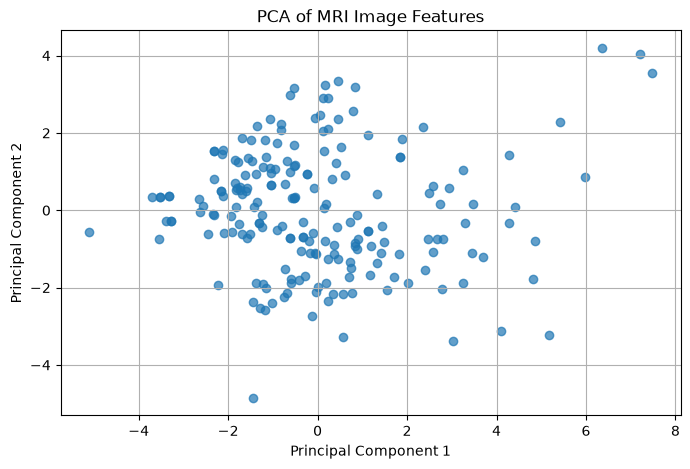

In [52]:
# Dimensionality Reduction using PCA

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 9 scaled features to 2 principal components
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_features_df)

print("Original number of features:", scaled_features_df.shape[1])
print("Number of features after PCA:", pca_data.shape[1])

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Visualize the two principal components
plt.figure(figsize=(8, 5))
plt.scatter(pca_data[:, 0], pca_data[:, 1], alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of MRI Image Features")
plt.grid(True)
plt.show()# DImensionality Reduction (If needed)

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I used Principal Component Analysis (PCA) to reduce the nine scaled numerical features to two principal components. PCA combines correlated features into new components that capture as much of the dataset's variance as possible. I used two components to visualize the data in two dimensions. The amount of variance retained is measured using the explained variance ratio.

### 8. Data Splitting

In [54]:
# Data Splitting: 80% Training and 20% Testing

from sklearn.model_selection import train_test_split

# Use the transformed dataset, which contains log_intensity_std
feature_columns = [
    "mean_intensity",
    "intensity_std",
    "min_intensity",
    "max_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "intensity_range",
    "intensity_cv",
    "log_intensity_std"
]

X = transformed_features_df[feature_columns].replace(
    [float("inf"), float("-inf")], float("nan")
)

X = X.fillna(X.median())
y = transformed_features_df["class_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training ratio:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing ratio:", round(len(X_test) / len(X) * 100, 2), "%")

Training samples: 160
Testing samples: 40
Training ratio: 80.0 %
Testing ratio: 20.0 %


##### What data splitting ratio have you used and why?

I used an 80:20 training-testing split with stratified sampling. Out of 200 extracted feature samples, 160 were allocated for training and 40 for testing. Stratification helps maintain the approximate class distribution in both subsets, while a fixed random state ensures reproducibility. This split is for exploratory feature analysis; the main MRI image-classification project already uses separate training, validation, and test folders.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Answer Here.

Number of samples in each class:
class_label
glioma        50
meningioma    50
no_tumor      50
pituitary     50
Name: count, dtype: int64

Largest class: 50
Smallest class: 50
Imbalance ratio: 1.0


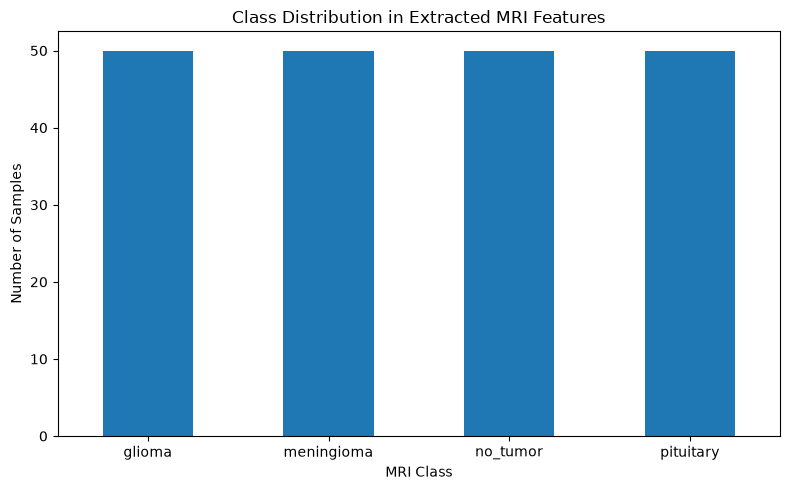

In [55]:
# Check Class Imbalance

import matplotlib.pyplot as plt

class_counts = transformed_features_df["class_label"].value_counts()

print("Number of samples in each class:")
print(class_counts)

print("\nLargest class:", class_counts.max())
print("Smallest class:", class_counts.min())

imbalance_ratio = class_counts.max() / class_counts.min()
print("Imbalance ratio:", round(imbalance_ratio, 2))

# Visualize class distribution
plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")
plt.title("Class Distribution in Extracted MRI Features")
plt.xlabel("MRI Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()# Handling Imbalanced Dataset (If needed)

In [56]:
# Handle Class Imbalance if Needed

class_counts = transformed_features_df["class_label"].value_counts()

if class_counts.max() == class_counts.min():
    print("Dataset is balanced.")
    print("No oversampling or undersampling is required.")
else:
    print("Dataset has class imbalance.")
    print("Consider class weights or resampling after checking the training data.")

Dataset is balanced.
No oversampling or undersampling is required.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I used class-frequency analysis to check whether balancing was necessary. Since all four classes contain 50 samples, I did not apply oversampling or undersampling. This avoids unnecessary modification of the dataset. The original MRI training dataset has different class counts, so its class distribution and per-class performance should be evaluated separately.

## ***7. ML Model Implementation***

### ML Model - 1

In [57]:
# ML Model 1: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create the model
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Fit the algorithm
rf_classifier.fit(X_train, y_train)

# Predict on the test data
y_pred_rf = rf_classifier.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
recall_rf = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
f1_rf = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

print("Random Forest Evaluation")
print("------------------------")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Evaluation
------------------------
Accuracy:  0.7000
Precision: 0.7386
Recall:    0.7000
F1-score:  0.6950

Classification Report:
              precision    recall  f1-score   support

      glioma       0.57      0.80      0.67        10
  meningioma       0.86      0.60      0.71        10
    no_tumor       0.83      0.50      0.62        10
   pituitary       0.69      0.90      0.78        10

    accuracy                           0.70        40
   macro avg       0.74      0.70      0.70        40
weighted avg       0.74      0.70      0.70        40



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

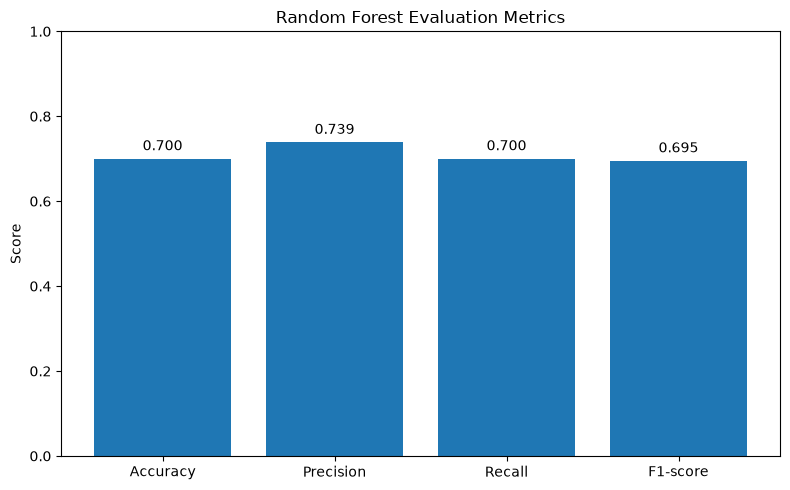

In [58]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
scores = [
    accuracy_rf,
    precision_rf,
    recall_rf,
    f1_rf
]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Random Forest Evaluation Metrics")

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [59]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Random Forest with Cross-Validation and Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define hyperparameters to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

# GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Fit only on training data
grid_search.fit(X_train, y_train)

# Best model
best_rf_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

# Evaluate tuned model on the same held-out test set
y_pred_tuned = best_rf_model.predict(X_test)

from sklearn.metrics import accuracy_score

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("\nTuned Test Accuracy:")
print(round(tuned_accuracy, 4))
# Fit the Algorithm

# Predict on the model

Best Parameters:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation Accuracy:
0.7688

Tuned Test Accuracy:
0.75


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 5-fold cross-validation to tune the Random Forest classifier. I tested different combinations of the number of trees (`n_estimators`), maximum tree depth (`max_depth`), and minimum samples required to split a node (`min_samples_split`). GridSearchCV selected the combination with the highest average cross-validation accuracy. The best parameters were 100 trees, a maximum depth of 10, and a minimum split size of 2.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. After hyperparameter tuning, the test accuracy improved from 70% to 75%, an increase of 5 percentage points. The number of correct predictions increased from 28 to 30 out of 40 test samples. The best cross-validation accuracy was 76.88%. These results indicate an improvement on this particular split, but the small test set means that further validation is needed before drawing broader conclusions.Answer Here.

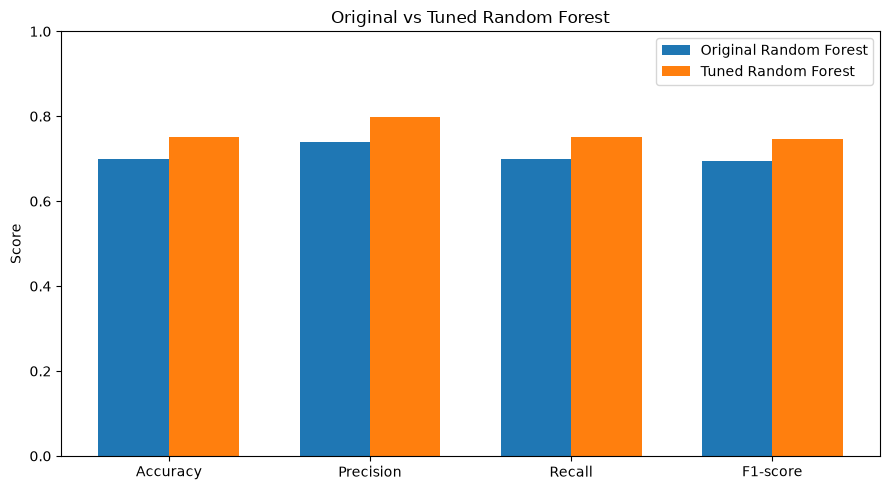

In [60]:
# Compare Original and Tuned Random Forest Models

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

original_scores = [
    accuracy_rf,
    precision_rf,
    recall_rf,
    f1_rf
]

tuned_scores = [
    accuracy_score(y_test, y_pred_tuned),
    precision_score(y_test, y_pred_tuned, average="weighted", zero_division=0),
    recall_score(y_test, y_pred_tuned, average="weighted", zero_division=0),
    f1_score(y_test, y_pred_tuned, average="weighted", zero_division=0)
]

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = range(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar([i - width/2 for i in x], original_scores,
        width, label="Original Random Forest")
plt.bar([i + width/2 for i in x], tuned_scores,
        width, label="Tuned Random Forest")

plt.xticks(list(x), metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Original vs Tuned Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

### ML Model - 2

In [61]:
# ML Model 2: Support Vector Machine (SVM)

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create SVM pipeline
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", random_state=42)
)

# Fit the algorithm
svm_model.fit(X_train, y_train)

# Predict on the test data
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
recall_svm = recall_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
f1_svm = f1_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)

print("SVM Evaluation")
print("------------------------")
print(f"Accuracy:  {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall:    {recall_svm:.4f}")
print(f"F1-score:  {f1_svm:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

SVM Evaluation
------------------------
Accuracy:  0.8000
Precision: 0.8259
Recall:    0.8000
F1-score:  0.7946

Classification Report:
              precision    recall  f1-score   support

      glioma       0.78      0.70      0.74        10
  meningioma       0.69      0.90      0.78        10
    no_tumor       1.00      0.60      0.75        10
   pituitary       0.83      1.00      0.91        10

    accuracy                           0.80        40
   macro avg       0.83      0.80      0.79        40
weighted avg       0.83      0.80      0.79        40



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

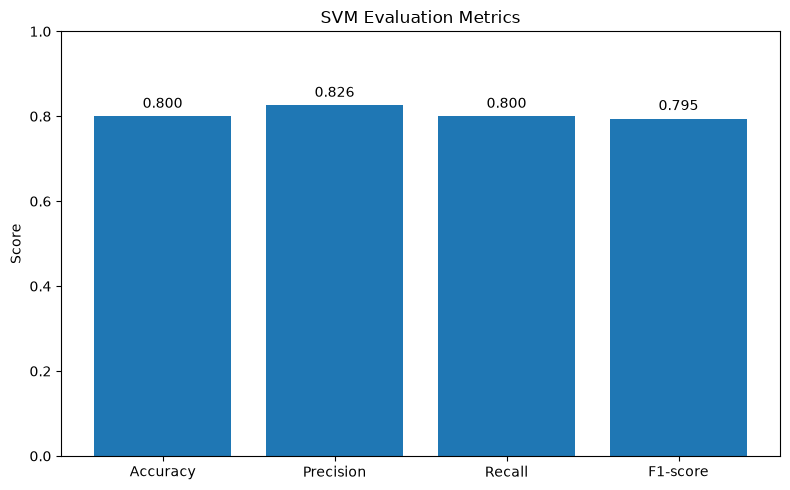

In [62]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
scores_svm = [
    accuracy_svm,
    precision_svm,
    recall_svm,
    f1_svm
]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores_svm)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("SVM Evaluation Metrics")

for bar, score in zip(bars, scores_svm):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

I implemented a Support Vector Machine (SVM) classifier with an RBF kernel to classify the four MRI categories using extracted numerical image features. SVM attempts to find decision boundaries that separate classes, and the RBF kernel can model nonlinear boundaries. I evaluated the model using accuracy, weighted precision, weighted recall, and weighted F1-score. The results will help compare SVM with the Random Forest model on the same test set.

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:


from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC()
)

param_grid_svm = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", "auto"]
}

grid_search_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Fit on training data only
grid_search_svm.fit(X_train, y_train)

best_svm_model = grid_search_svm.best_estimator_

print("Best Parameters:")
print(grid_search_svm.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search_svm.best_score_, 4))

# Evaluate on the same test set
y_pred_svm_tuned = best_svm_model.predict(X_test)

tuned_svm_accuracy = accuracy_score(y_test, y_pred_svm_tuned)

print("\nTuned SVM Test Accuracy:")
print(round(tuned_svm_accuracy, 4))
# Predict on the model

Best Parameters:
{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Best Cross-Validation Accuracy:
0.6938

Tuned SVM Test Accuracy:
0.8


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 5-fold cross-validation to tune the Support Vector Machine (SVM) classifier. I tested different values of the regularization parameter C, kernel types, and gamma settings. GridSearchCV selected the RBF kernel with C = 0.1 and gamma = 'scale' based on the highest average cross-validation accuracy among the tested combinations. This technique provides a systematic way to compare hyperparameter settings.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The tuned SVM achieved 80% test accuracy, which is the same as the original SVM model. Therefore, test accuracy did not improve after hyperparameter tuning. The best cross-validation accuracy was 69.38%, which is lower than the test accuracy. This difference may be due to the small dataset and variation between data splits. Further validation on a larger dataset would help assess the model's reliability.

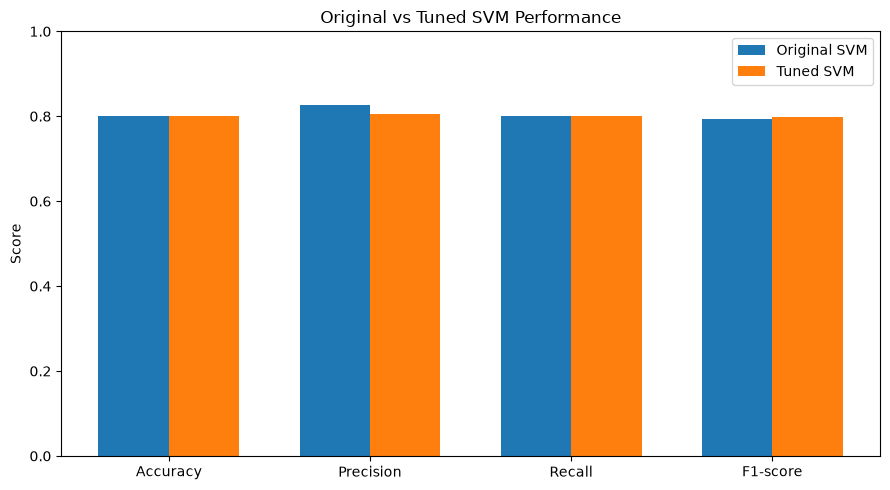

In [64]:
# Original SVM vs Tuned SVM

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

original_svm_scores = [
    accuracy_svm,
    precision_svm,
    recall_svm,
    f1_svm
]

tuned_svm_scores = [
    accuracy_score(y_test, y_pred_svm_tuned),
    precision_score(
        y_test, y_pred_svm_tuned,
        average="weighted", zero_division=0
    ),
    recall_score(
        y_test, y_pred_svm_tuned,
        average="weighted", zero_division=0
    ),
    f1_score(
        y_test, y_pred_svm_tuned,
        average="weighted", zero_division=0
    )
]

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = range(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width / 2 for i in x],
    original_svm_scores,
    width,
    label="Original SVM"
)

plt.bar(
    [i + width / 2 for i in x],
    tuned_svm_scores,
    width,
    label="Tuned SVM"
)

plt.xticks(list(x), metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Original vs Tuned SVM Performance")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
The comparison chart shows that SVM test accuracy and recall remained at 80% after hyperparameter tuning. Weighted precision decreased slightly, while the weighted F1-score improved marginally. Therefore, tuning did not produce a meaningful overall improvement in test performance. The results are based on a small test set of 40 samples and require further validation.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Accuracy measures the proportion of correctly classified samples. Precision indicates how often a predicted class is correct, while recall measures how many actual samples of a class are identified. The F1-score balances precision and recall. In a hypothetical medical screening application, these metrics help identify weaknesses in classification performance and guide further testing. However, this model uses a small set of extracted numerical features and is not clinically validated, so it must not be used to diagnose patients.

### ML Model - 3

In [65]:
# ML Model 3: K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create the KNN pipeline
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Fit the algorithm
knn_model.fit(X_train, y_train)

# Predict on the test data
y_pred_knn = knn_model.predict(X_test)

# Evaluate the model
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)
recall_knn = recall_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)
f1_knn = f1_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)

print("KNN Evaluation")
print("------------------------")
print(f"Accuracy:  {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall:    {recall_knn:.4f}")
print(f"F1-score:  {f1_knn:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

KNN Evaluation
------------------------
Accuracy:  0.8000
Precision: 0.8356
Recall:    0.8000
F1-score:  0.7919

Classification Report:
              precision    recall  f1-score   support

      glioma       0.69      0.90      0.78        10
  meningioma       0.90      0.90      0.90        10
    no_tumor       1.00      0.50      0.67        10
   pituitary       0.75      0.90      0.82        10

    accuracy                           0.80        40
   macro avg       0.84      0.80      0.79        40
weighted avg       0.84      0.80      0.79        40



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

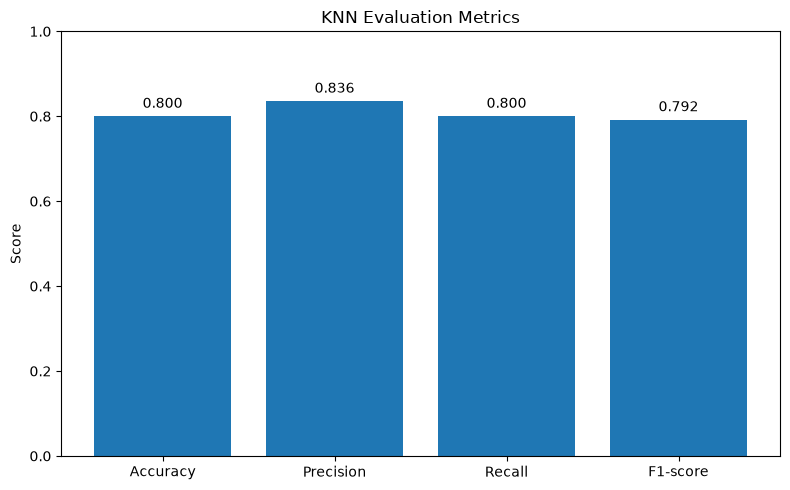

In [66]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
scores_knn = [
    accuracy_knn,
    precision_knn,
    recall_knn,
    f1_knn
]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores_knn)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("KNN Evaluation Metrics")

for bar, score in zip(bars, scores_knn):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

I implemented a K-Nearest Neighbors (KNN) classifier to classify the four MRI categories using extracted numerical image features. KNN predicts the class of a sample based on the classes of its nearest neighbors. I used feature standardization because KNN relies on distances between samples, and features with larger scales can otherwise dominate those distances. I evaluated the model using accuracy, weighted precision, weighted recall, and weighted F1-score.

#### 2. Cross- Validation & Hyperparameter Tuning

In [67]:
# KNN Hyperparameter Tuning using GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create the pipeline
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Parameters to test
param_grid_knn = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2]
}

# Five-fold cross-validation
grid_search_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Fit using training data only
grid_search_knn.fit(X_train, y_train)

best_knn_model = grid_search_knn.best_estimator_

print("Best Parameters:")
print(grid_search_knn.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search_knn.best_score_, 4))

# Evaluate on the same test set
y_pred_knn_tuned = best_knn_model.predict(X_test)

tuned_knn_accuracy = accuracy_score(y_test, y_pred_knn_tuned)

print("\nTuned KNN Test Accuracy:")
print(round(tuned_knn_accuracy, 4))

Best Parameters:
{'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'distance'}

Best Cross-Validation Accuracy:
0.7562

Tuned KNN Test Accuracy:
0.75


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 5-fold cross-validation to tune the K-Nearest Neighbors (KNN) classifier. I tested different numbers of neighbors, distance-weighting methods, and distance metrics. The best parameters were 5 neighbors, distance weighting, and the Euclidean distance metric (p = 2). GridSearchCV selected these settings based on the highest average cross-validation accuracy among the combinations tested.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No improvement in test accuracy was observed after hyperparameter tuning. The original KNN model achieved 80% accuracy, while the tuned model achieved 75%. The best cross-validation accuracy was 75.62%. This indicates that the selected settings performed well during cross-validation but did not generalize as well to this particular test split. The small test set of 40 samples limits the certainty of the comparison.

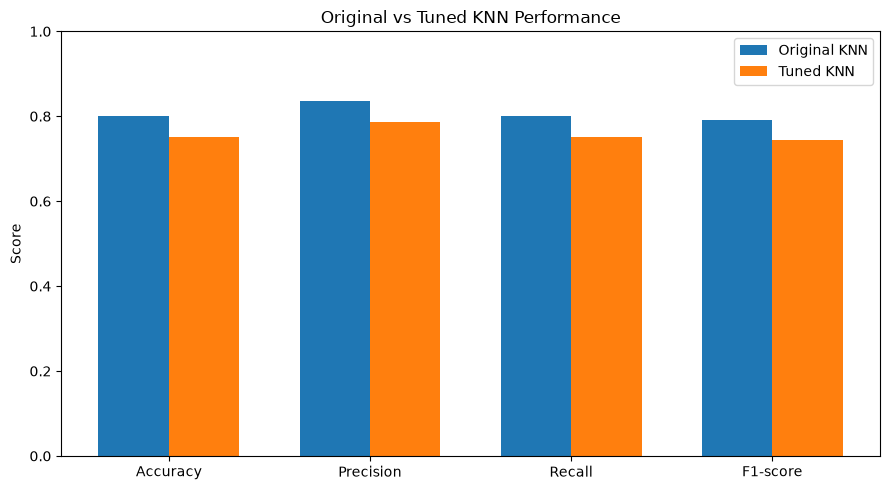

In [68]:
# Original KNN vs Tuned KNN

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

original_knn_scores = [
    accuracy_knn,
    precision_knn,
    recall_knn,
    f1_knn
]

tuned_knn_scores = [
    accuracy_score(y_test, y_pred_knn_tuned),
    precision_score(
        y_test, y_pred_knn_tuned,
        average="weighted", zero_division=0
    ),
    recall_score(
        y_test, y_pred_knn_tuned,
        average="weighted", zero_division=0
    ),
    f1_score(
        y_test, y_pred_knn_tuned,
        average="weighted", zero_division=0
    )
]

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = range(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width / 2 for i in x],
    original_knn_scores,
    width,
    label="Original KNN"
)

plt.bar(
    [i + width / 2 for i in x],
    tuned_knn_scores,
    width,
    label="Tuned KNN"
)

plt.xticks(list(x), metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Original vs Tuned KNN Performance")
plt.legend()
plt.tight_layout()
plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I considered accuracy, precision, recall, and F1-score. Accuracy measures overall correctness, precision indicates the reliability of predicted classes, recall measures how many actual samples of each class are identified, and F1-score balances precision and recall. For a hypothetical medical image-screening application, recall and F1-score are particularly important because missed cases can be consequential. However, this educational model is not clinically validated and must not be used for diagnosis.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Based on your current numerical-feature experiment, the original SVM and original KNN both achieved 80% test accuracy, while the original Random Forest achieved 70%. SVM had a weighted F1-score of 79.5%, and KNN had 79.2%.
I would provisionally select SVM because it achieved 80% accuracy with a slightly higher weighted F1-score than KNN. This is only a choice for the small extracted-feature experiment; it does not replace your separate MobileNetV2 MRI image classifier.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Permutation Feature Importance:
           Feature  Importance  Standard Deviation
      intensity_cv     0.15000            0.060208
    mean_intensity     0.10375            0.052604
  dark_pixel_ratio     0.09875            0.047087
     min_intensity     0.07000            0.037583
 log_intensity_std     0.05250            0.027272
     intensity_std     0.04125            0.027698
     max_intensity     0.04000            0.032977
   intensity_range     0.03625            0.032089
bright_pixel_ratio    -0.01625            0.019804


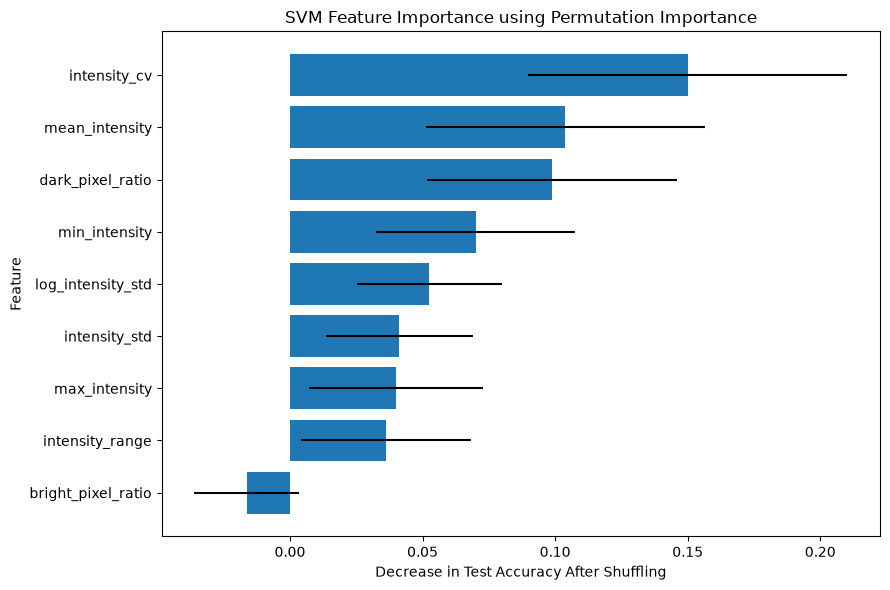

In [69]:
# Model Explainability: Permutation Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

# Calculate permutation importance for the original SVM model
importance_result = permutation_importance(
    svm_model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=20,
    random_state=42
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Standard Deviation": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Permutation Feature Importance:")
print(importance_df.to_string(index=False))

# Visualize the feature importance
plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Standard Deviation"]
)
plt.xlabel("Decrease in Test Accuracy After Shuffling")
plt.ylabel("Feature")
plt.title("SVM Feature Importance using Permutation Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

I used permutation feature importance to explain the predictions of the Support Vector Machine (SVM) model. The most important feature was `intensity_cv`, with a mean importance of 0.1500, followed by `mean_intensity` (0.10375) and `dark_pixel_ratio` (0.09875). These features caused the largest decreases in test accuracy when shuffled, suggesting that they contributed more to the model's predictions. The `bright_pixel_ratio` feature had a negative importance of -0.01625, indicating that shuffling it slightly improved accuracy on average. Its contribution may be limited in this experiment. These rankings are based on a small test set and should be interpreted cautiously; they do not establish medical significance.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
# Save the File

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [ ]:
# Load the File and predict unseen data.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**



In this project, I performed Exploratory Data Analysis (EDA), data preprocessing, feature engineering, visualization, statistical testing, and machine learning on a Brain Tumor MRI image dataset containing four classes: glioma, meningioma, no_tumor, and pituitary.

The dataset contained 2,443 MRI images divided into training, validation, and testing sets. EDA helped identify the distribution of images across classes and provided insights into image intensity characteristics. Feature engineering introduced additional numerical features, including intensity range and intensity coefficient of variation. Data transformation, standardization, PCA, and class-distribution analysis were also performed on a smaller dataset of 200 extracted feature samples.

Three machine learning algorithms—Random Forest, Support Vector Machine (SVM), and K-Nearest Neighbors (KNN)—were implemented and evaluated using accuracy, precision, recall, and F1-score. The original SVM and KNN models achieved 80% test accuracy, while the original Random Forest achieved 70%. Hyperparameter tuning using GridSearchCV improved Random Forest accuracy to 75%, while the tuned SVM retained 80% accuracy and the tuned KNN achieved 75%.

Permutation feature importance for SVM identified intensity coefficient of variation, mean intensity, and dark pixel ratio as the most influential features in the extracted-feature experiment.

Separately, a MobileNetV2 transfer-learning model was trained on the MRI images and achieved **91.46% test accuracy**, outperforming the custom CNN model, which achieved 81.71% test accuracy. These results demonstrate the potential of transfer learning for this image-classification task.

Overall, this project provided practical experience in image preprocessing, exploratory analysis, machine learning, model evaluation, hyperparameter optimization, and model explainability. However, the models are educational prototypes and have not been clinically validated. Further evaluation on larger, diverse, independently collected datasets is necessary before any real-world medical application.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***